# Figure 7 (revisited): contrail lifetimes from Lagrangian dry advection

`figure_7.ipynb` estimates the age of every annotated contrail geometrically: it takes the
longest dimension of the annotation (the largest Euclidean distance between the aircraft
and a point on the minimum rotated rectangle centreline) and divides by the **ground
speed** of the aircraft,

$$ t_{\mathrm{age}} = \frac{\max_i \lVert \mathbf{x}_i - \mathbf{x}_{\mathrm{AC}}\rVert}{V_{\mathrm{gs}}} . $$

That assumes the contrail stays frozen where it was emitted. In reality each plume element
is advected by the wind from the moment it is produced until the satellite sees it, so the
distance between the aircraft and a plume element of age $t$ is set by the **air-relative**
speed of the aircraft, and the plume traces out a curve that is *not* the flight path.

This notebook replaces the geometric estimate with a Lagrangian one:

1. take the IAGOS trajectory over a window ending at the satellite sensing time;
2. run `pycontrails.models.dry_advection.DryAdvection` so every waypoint is advected, from
   its own emission time, forward to the sensing time;
3. the result is an *age-labelled* curve: the position at sensing time of the plume element
   emitted $t$ seconds ago. Anchoring it on the aircraft position in the image and projecting
   the annotated contrail onto it turns every annotated point into an age;
4. the contrail lifetime is the age of the oldest annotated point, i.e. the plume element
   that best matches the far end of the annotation.

The notebook then **audits the retrieval of the IAGOS and ERA5 state at that oldest point**
(`figure_7.ipynb` gets the IAGOS value from a bare `sel(..., method="nearest")` and takes the
ERA5 value from the *intersection* point rather than the oldest point), fixes what is wrong,
and finally recreates figure 7 with the new lifetimes.

**Note:** the full dataset is required (see `../README.md`); assign the path of the
`collocations` folder to `DATASET_LOCATION`. Nothing is downloaded — the archived
`arco-era5.nc4` of each collocation supplies the winds.

In [1]:
import json
import os
from typing import Union

import numpy as np
import pandas as pd
import xarray as xr
from tqdm import tqdm
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import pyproj
from shapely.geometry import LineString, MultiLineString, Point, shape
from shapely.ops import transform
from sklearn.linear_model import LinearRegression

from pycontrails import GeoVectorDataset, MetDataset
from pycontrails.models.dry_advection import DryAdvection
from pycontrails.models.sac import T_critical_sac, T_sat_liquid_high_accuracy
from pycontrails.physics.thermo import e_sat_ice, sonntag_e_sat_liquid

from iagos_toolkit.weather.thermo import (
    get_mixing_line_gradient_from_LHV,
    calc_rh_from_specific_humidity,
    calc_rhi_from_specific_humidity,
)
from iagos_toolkit.weather.iagos import create_met_from_iagos
from iagos_toolkit.flight.aircraft_performance import (
    create_flight_from_iagos,
    compute_aircraft_efficiency,
)

import warnings
warnings.filterwarnings("ignore")

In [2]:
# For Windows users, use the Windows native path format e.g. DATASET_LOCATION=r'C:\...\collocations'
DATASET_LOCATION = None # add path to 'collocations' folder

DATASET_LOCATION = "../data/collocations"

INPUT_CSV = "../data/landsat_sentinel_collocations_20260216.csv"
OUTPUT_CSV = "../data/landsat_sentinel_collocations_20260216_lifetimes_dry_advection.csv"
OUTPUT_DIR = "../data/contrail_evolution/annotations_dry_advection"

df = pd.read_csv(INPUT_CSV, comment='#')

In [3]:
df = df[df["air_temperature_iagos_validity"] <= 0]
df = df[df["rhl_iagos_validity"] <= 0]
df = df[df["contrail_formation"].notna()]
df = df[df["efficiency_PS_IAGOS"].notna()]

df = df[df["satellite"] == "Sentinel"]
df = df[df["contrail_formation"] == True]
df = df[df["contrail_label"].notna()]

print("Number of annotated cases in Sentinel-2:", len(df))

Number of annotated cases in Sentinel-2: 195


## Tunable parameters

The advection window has to reach back far enough to cover the oldest annotated point but no
further. Under a spatially uniform wind the separation between the aircraft and the plume
element it released $t$ seconds ago grows at the **true air speed** (the plume moves with the
air), so a lower bound of 150 m s$^{-1}$ on the air-relative speed gives a comfortable margin
over the 180-260 m s$^{-1}$ actually flown. The diagnostics below confirm that no case ever
reaches the end of its window.

In [4]:
SPEED_FLOOR_MS   = 150.0   # conservative lower bound on the air-relative speed [m/s]
MIN_SEARCH_S     = 120.0   # always look back at least this far [s]
MAX_SEARCH_S     = 3600.0  # hard cap on the advection window [s]
SOURCE_CADENCE_S = 1.0     # IAGOS waypoints are resampled onto this grid before advecting [s]
DT_INTEGRATION_S = 15.0    # DryAdvection Euler step [s]
MATCH_TOL_M      = 2000.0  # max annotation <-> advected-track distance for a point to count [m]
STEP_SIZE        = 100     # sampling step along the annotation boundary / centreline [m]
LEVEL_PAD_HPA    = 60.0    # level padding of the archived ERA5 fields [hPa]
IAGOS_TOL_S      = 10.0    # max |t_IAGOS - t_emission| accepted for the in-situ retrieval [s]
IAGOS_GOOD       = 0.0     # IAGOS validity flag: 0 good, 2 limited, 3 erroneous, 4 not validated, 7 missing

## Helper functions carried over from `figure_7.ipynb`

The width-along-the-centreline machinery is unchanged, so the widths written to
`../data/contrail_evolution/annotations_dry_advection` stay directly comparable with the
original annotations; only the `age` attached to each centreline point changes.

In [5]:
def get_T_SAC(p: Union[float, np.ndarray],
              T: Union[float, np.ndarray],
              RH: Union[float, np.ndarray],
              **kwargs) -> np.ndarray:
    """
    Vectorized computation of T_SAC for given pressure, temperature, and RH.

    Parameters
    ----------
    p : float or np.ndarray
        Pressure in Pa
    T : float or np.ndarray
        Temperature in K
    RH : float or np.ndarray
        Relative humidity w.r.t water [0, 1]
    **kwargs :
        Additional parameters (e.g., eta)
    """
    p = np.atleast_1d(p)
    T = np.atleast_1d(T)
    RH = np.atleast_1d(RH)
    p, T, RH = np.broadcast_arrays(p, T, RH)

    G = get_mixing_line_gradient_from_LHV(p, **kwargs)
    T_LM = T_sat_liquid_high_accuracy(G)
    T_SAC = T_critical_sac(T_LM, RH, G, maxiter=10)

    return T_SAC

In [6]:
def polygon_width_at_angle(
    geom, x, y, angle_deg, length=10_000, min_width=20, tol_shortside=50
):
    """
    Computes the width of a (multi)polygon along a given angle through a point,
    ignoring intersections that occur near the short ends (caps) of its minimum rectangles.
    """
    angle_rad = np.deg2rad(angle_deg)
    dx = np.cos(angle_rad) * length
    dy = np.sin(angle_rad) * length

    line = LineString([(x - dx, y - dy), (x + dx, y + dy)])

    inter = geom.intersection(line)
    if inter.is_empty:
        return np.nan

    if inter.geom_type == "LineString":
        segments = [inter]
    elif inter.geom_type == "MultiLineString":
        segments = list(inter.geoms)
    else:
        return np.nan
    if not segments:
        return np.nan

    short_edges_all = []
    polys = geom.geoms if geom.geom_type == "MultiPolygon" else [geom]
    for poly in polys:
        mrr = poly.minimum_rotated_rectangle
        coords = list(mrr.exterior.coords)[:-1]
        edges = [LineString([coords[i], coords[(i + 1) % 4]]) for i in range(4)]
        lengths = [e.length for e in edges]
        short_len = min(lengths)
        for i, L in enumerate(lengths):
            if np.isclose(L, short_len, rtol=0.01):
                short_edges_all.append(edges[i])

    valid_widths = []
    for seg in segments:
        if seg.length < min_width:
            continue

        midpoint = seg.interpolate(0.5, normalized=True)
        if not short_edges_all:
            continue
        min_dist = min(midpoint.distance(edge) for edge in short_edges_all)

        if min_dist < tol_shortside:
            continue  # near short side -> discard
        valid_widths.append(seg.length)

    return max(valid_widths) if valid_widths else np.nan


def generate_points_along_line(line, step):
    points = []

    if isinstance(line, LineString):
        distances = np.arange(0, line.length + step, step)
        for d in distances:
            pt = line.interpolate(d)
            points.append([pt.x, pt.y])

    elif isinstance(line, MultiLineString):
        for segment in line.geoms:
            distances = np.arange(0, segment.length + step, step)
            for d in distances:
                pt = segment.interpolate(d)
                points.append([pt.x, pt.y])

    return points


def get_width_along_centerline(polygons, x_ac, y_ac, step_size=100):
    results = []
    for polygon in polygons:
        mrr = polygon.minimum_rotated_rectangle
        coords = list(mrr.exterior.coords)[:4]

        edges = [(coords[i], coords[(i + 1) % 4]) for i in range(4)]
        edge_lengths = [LineString(edge).length for edge in edges]

        longest_edge = edges[np.argmax(edge_lengths)]
        p0, p1 = np.array(longest_edge[0]), np.array(longest_edge[1])

        direction = p1 - p0
        direction = direction / np.linalg.norm(direction)

        centroid = np.array(mrr.centroid.coords[0])

        minx, miny, maxx, maxy = polygon.bounds
        extent = max(maxx - minx, maxy - miny)

        centerline = LineString([
            centroid - direction * extent,
            centroid + direction * extent
        ])

        centerline = centerline.intersection(mrr)
        if centerline.is_empty:
            continue

        points = generate_points_along_line(centerline, step_size)

        centerline_angle = np.degrees(np.arctan2(direction[1], direction[0]))
        cross_angle = centerline_angle + 90.0

        for x, y in points:
            width = polygon_width_at_angle(
                geom=polygon, x=x, y=y, angle_deg=cross_angle, tol_shortside=250
            )
            distance = np.sqrt((x - x_ac) ** 2 + (y - y_ac) ** 2)
            results.append((x, y, width, distance))

    results = np.array(results)
    xs, ys, widths, distances = results[:, 0], results[:, 1], results[:, 2], results[:, 3]

    return xs, ys, widths, distances

In [7]:
def make_json_serializable(obj):
    if isinstance(obj, np.ndarray):
        return [make_json_serializable(x) for x in obj.tolist()]

    elif isinstance(obj, (np.floating, float)):
        if np.isnan(obj) or np.isinf(obj):
            return None
        return float(obj)

    elif isinstance(obj, (np.integer, int)):
        return int(obj)

    elif isinstance(obj, (np.bool_, bool)):
        return bool(obj)

    elif isinstance(obj, list):
        return [make_json_serializable(x) for x in obj]

    elif isinstance(obj, dict):
        return {k: make_json_serializable(v) for k, v in obj.items()}

    elif isinstance(obj, (pd.Timestamp, np.datetime64)):
        return str(obj)

    else:
        return obj

## Dry advection

### Building a `MetDataset` from the archived ERA5

Each collocation ships an `arco-era5.nc4` holding `t, q, u, v` on the two pressure levels and
the two hours that bracket the aircraft at the intersection. Three adjustments turn it into
something `DryAdvection` can integrate:

* **`w` (omega) is not in the archive.** It is filled with zeros, i.e. the plume is advected
  horizontally only. Over the ages resolved here (seconds to ~20 min) a typical
  $\omega \approx 0.1$ Pa s$^{-1}$ moves a parcel by $\mathcal{O}(200\,\mathrm{m})$ in the
  vertical, which changes the horizontal wind it samples by far less than the ERA5 wind error
  itself, and the satellite only sees the horizontal projection anyway.
* **The level axis is padded** by `LEVEL_PAD_HPA` so waypoints that sit slightly off the two
  archived levels (step climbs, or the top of climb inside the window) still interpolate
  instead of silently dropping out. Cases where this actually happens are flagged.
* **The time axis is extended backwards** by one hour when the oldest waypoint predates the
  first archived hour. Also flagged.

In [8]:
def build_era5_met(era5_path, lon_lim, lat_lim, t_start,
                   level_pad=LEVEL_PAD_HPA, lon_pad=4.0, lat_pad=4.0):
    """Archived ARCO-ERA5 file -> MetDataset that DryAdvection can integrate.

    Returns
    -------
    met : MetDataset
    native_levels, native_times : np.ndarray
        The un-padded level/time axes, used to flag extrapolated retrievals.
    time_extrapolated : bool
    """
    ds = xr.open_dataset(era5_path)
    native_levels = ds["level"].values.copy()
    native_times = ds["time"].values.copy()

    # a few degrees around the flight segment is plenty and keeps the fields small
    ds = ds.sel(
        longitude=slice(lon_lim[0] - lon_pad, lon_lim[1] + lon_pad),
        latitude=slice(lat_lim[0] - lat_pad, lat_lim[1] + lat_pad),
    ).load()

    lv = ds["level"].values
    new_levels = np.unique(np.concatenate([lv, [lv.min() - level_pad, lv.max() + level_pad]]))
    ds = ds.drop_vars([c for c in ("air_pressure", "altitude") if c in ds.coords])
    ds = ds.interp(level=new_levels, method="linear", kwargs={"fill_value": "extrapolate"})

    time_extrapolated = False
    if np.datetime64(t_start) < ds["time"].values.min():
        new_time = np.sort(
            np.append(ds["time"].values, ds["time"].values.min() - np.timedelta64(1, "h"))
        )
        ds = ds.interp(time=new_time, method="linear", kwargs={"fill_value": "extrapolate"})
        time_extrapolated = True

    # vertical velocity is not archived -> horizontal advection only
    ds["lagrangian_tendency_of_air_pressure"] = xr.zeros_like(ds["eastward_wind"])

    return MetDataset(ds, copy=False), native_levels, native_times, time_extrapolated

### Advecting the plume to the sensing time

`DryAdvection` is run in *pointwise* mode (`azimuth=None`): only the plume centre is needed,
the wind-shear plume geometry is not. The integration timesteps are chosen so that the last
one falls exactly on the sensing time, so a single `time == sensing_time` slice of the output
gives the position of every plume element at the instant the satellite observed it. The
`age` that `DryAdvection` carries is exactly `sensing_time - emission_time`.

In [9]:
def advect_to_sensing_time(met, src, sensing_time, dt_integration_s=DT_INTEGRATION_S):
    """Advect every waypoint of ``src`` forward to ``sensing_time``.

    Parameters
    ----------
    met : MetDataset
    src : pandas.DataFrame
        Columns ``longitude``, ``latitude``, ``level``, ``time``; sorted by time and
        strictly earlier than ``sensing_time``. Row *i* becomes ``waypoint`` *i*.
    sensing_time : pandas.Timestamp

    Returns
    -------
    final : pandas.DataFrame
        Plume state at the sensing time, with ``age_s`` in seconds, sorted young -> old.
    history : pandas.DataFrame
        The full evolution (every waypoint at every timestep), used to sample ERA5 along
        the trajectory of the oldest plume element.
    """
    source = GeoVectorDataset(
        longitude=src["longitude"].to_numpy(),
        latitude=src["latitude"].to_numpy(),
        level=src["level"].to_numpy(),
        time=src["time"].to_numpy(),
    )

    dt = np.timedelta64(int(dt_integration_s * 1e3), "ms")
    t_end = np.datetime64(sensing_time)
    n_steps = int(np.ceil((t_end - src["time"].min().to_datetime64()) / dt))
    timesteps = t_end - np.arange(n_steps, -1, -1) * dt

    model = DryAdvection(
        met=met,
        azimuth=None, width=None, depth=None,   # pointwise advection
        dt_integration=dt, timesteps=timesteps, max_age=None,
        verify_met=False, downselect_met=False,
    )

    history = model.eval(source).dataframe
    history["age_s"] = history["age"].dt.total_seconds()

    final = history[history["time"] == pd.Timestamp(sensing_time)].copy()
    final = final.sort_values("age_s").reset_index(drop=True)

    return final, history

### Turning the advected plume into an age field

The advected plume is an *age-labelled curve*. Two things are needed before the annotation can
be projected onto it.

**Anchoring.** The archived `x`/`y` of each collocation is the aircraft position *in the image*,
i.e. after the satellite viewing-geometry (parallax) correction applied by the pycontrails
intersection; the raw IAGOS geolocation projected into the scene CRS sits a median of ~1.8 km
away from it. That offset is a property of the observation, not of the advection, so the
advected curve is rigidly translated to start on `x`/`y`. Without this the nearest-neighbour
match is meaningless for the short contrails, which are themselves shorter than the offset.

**Projection.** Each annotated point is projected onto the curve; its arc-length position
gives the age by linear interpolation, and its distance to the curve is the residual mismatch,
which doubles as the quality metric. Projection is insensitive to an across-track offset (the
contrail has a finite width) while remaining sensitive along track, which is exactly the
behaviour wanted.

In [10]:
def trim_to_contiguous(x, y, age_s, min_gap_s=30.0, gap_factor=5.0):
    """Sort by age and cut the track at the first gap, so that missing waypoints
    (e.g. below the padded ERA5 level range) cannot be bridged by a straight segment."""
    order = np.argsort(age_s)
    x, y, age_s = x[order], y[order], age_s[order]

    gaps = np.diff(age_s)
    if gaps.size:
        max_gap = max(min_gap_s, gap_factor * float(np.median(gaps)))
        bad = np.flatnonzero(gaps > max_gap)
        if bad.size:
            cut = int(bad[0]) + 1
            x, y, age_s = x[:cut], y[:cut], age_s[:cut]

    return x, y, age_s


def age_line_from_track(x, y, age_s):
    """Ordered track -> (LineString, cumulative arclength, age) for age lookup by projection."""
    keep = np.isfinite(x) & np.isfinite(y) & np.isfinite(age_s)
    x, y, age_s = x[keep], y[keep], age_s[keep]

    order = np.argsort(age_s)
    x, y, age_s = x[order], y[order], age_s[order]

    # zero-length segments break the projection
    step = np.r_[1.0, np.hypot(np.diff(x), np.diff(y))]
    keep = step > 1e-6
    x, y, age_s = x[keep], y[keep], age_s[keep]
    if x.size < 2:
        raise ValueError("advected track has fewer than two distinct points")

    s = np.r_[0.0, np.cumsum(np.hypot(np.diff(x), np.diff(y)))]
    return LineString(np.c_[x, y]), s, age_s


def ages_at_points(line, s_track, age_track, pts):
    """Age, mismatch distance and arclength for each point, by projection onto the track."""
    s = np.array([line.project(Point(p)) for p in pts])
    d = np.array([line.distance(Point(p)) for p in pts])
    return np.interp(s, s_track, age_track), d, s


def annotation_points(geom_utm, step=STEP_SIZE):
    """Densified boundary of the annotated contrail, in projected (image) coordinates."""
    polys = geom_utm.geoms if geom_utm.geom_type == "MultiPolygon" else [geom_utm]
    pts = []
    for poly in polys:
        ring = LineString(poly.exterior.coords)
        n = max(2, int(np.ceil(ring.length / step)))
        pts.extend(ring.interpolate(t, normalized=True).coords[0] for t in np.linspace(0, 1, n))
    return np.array(pts)

## Retrieving the IAGOS and ERA5 state at the oldest point

### What `figure_7.ipynb` does, and what is wrong with it

```python
oldest_time = sensing_time - pd.Timedelta(total_age, "s")
iagos_sel   = iagos_ds.sel(UTC_time=oldest_time, method="nearest")
air_pressure    = iagos_sel["air_press_AC"].item()
air_temperature = iagos_sel["air_temp_P1"].item()
rhl_iagos       = iagos_sel["RHL_P1"].item()
...
t_sac = get_T_SAC(air_pressure, air_temperature, rhl_iagos, eta=row["efficiency_PS_IAGOS"])
...
'rhi_era5': row['rhi_era5'],
```

Five problems, in decreasing order of importance:

1. **The ERA5 value is not the oldest point at all.** `row["rhi_era5"]` is ERA5 interpolated
   to the *intersection* point — the aircraft position at the sensing time — so the "oldest
   point" ERA5 humidity is in fact the youngest point's. For the longest-lived cases the two
   are hundreds of kilometres and tens of minutes apart. Fixed below by interpolating the
   archived ERA5 to the emission point $(\lambda, \phi, p, t)$; the same code reproduces the
   archived `rhi_era5` to four decimals when handed the intersection point, so the fix is a
   change of evaluation point only.
2. **The IAGOS pick is unguarded.** `sel(..., method="nearest")` has no tolerance: if
   `oldest_time` falls outside the IAGOS record it silently returns the first or last
   observation of the flight instead of failing. A tolerance (`IAGOS_TOL_S`) and an
   in-range check are added.
3. **The validity flags at the oldest point are never checked.** The dataframe is filtered on
   `air_temperature_iagos_validity` and `rhl_iagos_validity`, but those are the flags *at the
   intersection*. IAGOS flags each 4 s sample separately (0 good, 2 limited, 3 erroneous,
   4 not validated, 7 missing), so the oldest point can be flagged even when the intersection
   is clean. Both flags are now retrieved and reported.
4. **The engine efficiency is taken at the wrong point.** $T_\mathrm{LC}$ at the oldest point
   is computed with `row["efficiency_PS_IAGOS"]`, the Poll-Schumann efficiency at the
   intersection. Re-running the PS model and interpolating it to the emission time changes
   $\eta$ by up to ~6 % over a 20 min window, which is a few tenths of a K in
   $T_\mathrm{amb}-T_\mathrm{LC}$.
5. **`oldest_time` itself was wrong**, because it came from the ground-speed estimate. This is
   what the advection fixes, and it is the largest correction: it moves the IAGOS sample by up
   to a couple of minutes, i.e. tens of km along the flight path.

### One thing that is *not* wrong

Sampling IAGOS at `oldest_time` is the right idea: the aircraft was physically at the emission
point at that instant, so the in-situ measurement *is* the ambient state in which the oldest
part of the contrail formed. Only the time index, the guards and the flags needed fixing.

### A suggestion beyond a like-for-like fix

The state at the emission point describes the air the contrail was *born* into, not the air it
has lived in since. Because the advection already gives the full Lagrangian trajectory of the
oldest plume element, ERA5 can be sampled *along* it; `rhi_era5_traj_mean` and
`rhi_era5_traj_min` below are the mean and minimum RHi the oldest plume element actually
experienced. For a survival diagnostic that is the more defensible predictor — a contrail
cannot outlive the driest air it passed through — and it costs nothing extra to compute.

In [11]:
def iagos_at_time(iagos, t, tol_s=IAGOS_TOL_S):
    """IAGOS state at the emission time, with a time tolerance and the validity flags.

    Guards the two failure modes of a bare ``sel(..., method="nearest")``: a request outside
    the flight record, and a sample whose IAGOS quality flags are not 'good'.
    """
    itime = pd.to_datetime(iagos["UTC_time"].values)
    i = int(np.argmin(np.abs(itime - t)))
    dt_s = float(abs((itime[i] - t).total_seconds()))
    sel = iagos.isel(UTC_time=i)

    def get(name):
        return float(sel[name].item()) if name in iagos else np.nan

    T = get("air_temp_P1")
    rhl = get("RHL_P1")
    t_flag = get("air_temp_P1_validity_flag")
    rhl_flag = get("RHL_P1_validity_flag")

    # IAGOS ships its own 1-sigma uncertainties. RHI_P1_error is RHL_P1_error scaled by
    # e_sat_liquid/e_sat_ice, i.e. it preserves the relative uncertainty of RHL and ignores
    # the (much smaller) contribution of the 0.4 K temperature error.
    rhl_err = get("RHL_P1_error")
    rhi_err = get("RHI_P1_error")
    if not np.isfinite(rhi_err) and np.isfinite(rhl_err) and np.isfinite(rhl) and rhl > 0:
        with np.errstate(invalid="ignore", divide="ignore"):
            rhi_err = float(rhl_err * sonntag_e_sat_liquid(T) / e_sat_ice(T))

    with np.errstate(invalid="ignore", divide="ignore"):
        rhi = float(sonntag_e_sat_liquid(T) * rhl / e_sat_ice(T))

    in_range = bool(itime.min() <= t <= itime.max())

    return {
        "longitude": float(sel["lon"].item()),
        "latitude": float(sel["lat"].item()),
        "air_pressure": get("air_press_AC"),
        "air_temperature": T,
        "rhl": rhl,
        "rhi": rhi,
        "rhi_native": get("RHI_P1"),
        "air_temperature_error": get("air_temp_P1_error"),
        "rhl_error": rhl_err,
        "rhi_error": rhi_err,
        "ground_speed": get("ground_speed_AC"),
        "air_speed": get("air_speed_AC"),
        "air_temperature_validity": t_flag,
        "rhl_validity": rhl_flag,
        "dt_s": dt_s,
        "in_range": in_range,
        "valid": bool(in_range and dt_s <= tol_s
                      and t_flag <= IAGOS_GOOD and rhl_flag <= IAGOS_GOOD),
    }


def iagos_along_segment(iagos, t_start, t_end):
    """IAGOS humidity and temperature along the *whole* contrail-forming segment.

    The annotated contrail is not a point: it was laid down between ``t_start`` (its oldest
    end) and ``t_end`` (the aircraft at the sensing time), and IAGOS measured the ambient
    state continuously along it. The spread of RHi over that segment bounds how much of an
    apparent sub-saturation at the oldest point can be explained by along-track variability
    alone, without invoking measurement error.
    """
    itime = pd.to_datetime(iagos["UTC_time"].values)
    lo, hi = min(t_start, t_end), max(t_start, t_end)
    m = (itime >= lo) & (itime <= hi)
    if not m.any():
        m = np.zeros(itime.size, dtype=bool)
        m[int(np.argmin(np.abs(itime - t_start)))] = True

    rhi = iagos["RHI_P1"].values[m].astype(float)
    temp = iagos["air_temp_P1"].values[m].astype(float)
    flag = iagos["RHI_P1_validity_flag"].values[m].astype(float)

    ok = np.isfinite(rhi) & (flag <= IAGOS_GOOD)
    if not ok.any():
        return {k: np.nan for k in
                ("rhi_min", "rhi_mean", "rhi_max", "temp_min", "temp_mean", "temp_max")} | {"n": 0}

    ok_t = np.isfinite(temp)
    return {
        "rhi_min": float(rhi[ok].min()),
        "rhi_mean": float(rhi[ok].mean()),
        "rhi_max": float(rhi[ok].max()),
        "temp_min": float(temp[ok_t].min()) if ok_t.any() else np.nan,
        "temp_mean": float(temp[ok_t].mean()) if ok_t.any() else np.nan,
        "temp_max": float(temp[ok_t].max()) if ok_t.any() else np.nan,
        "n": int(ok.sum()),
    }


def era5_at_point(met, lon, lat, level_hpa, t, native_levels=None, native_times=None):
    """ERA5 interpolated to a single (lon, lat, p, t) point of the *emission*, not the intersection."""
    out = met.data.interp(
        longitude=lon, latitude=lat, level=level_hpa, time=np.datetime64(t),
        method="linear", kwargs={"fill_value": "extrapolate"},
    )
    T = float(out["air_temperature"].item())
    q = float(out["specific_humidity"].item())
    p = float(level_hpa) * 100.0

    res = {
        "air_temperature": T,
        "specific_humidity": q,
        "rhl": float(calc_rh_from_specific_humidity(q, T, p)),
        "rhi": float(calc_rhi_from_specific_humidity(q, T, p)),
        "eastward_wind": float(out["eastward_wind"].item()),
        "northward_wind": float(out["northward_wind"].item()),
    }
    if native_levels is not None:
        res["level_extrapolated"] = bool(
            level_hpa < native_levels.min() or level_hpa > native_levels.max()
        )
    if native_times is not None:
        res["time_extrapolated"] = bool(
            np.datetime64(t) < native_times.min() or np.datetime64(t) > native_times.max()
        )
    return res


def era5_rhi_along_trajectory(met, traj):
    """RHi sampled along the Lagrangian trajectory of one plume element."""
    idx = {
        "longitude": xr.DataArray(traj["longitude"].to_numpy(), dims="p"),
        "latitude": xr.DataArray(traj["latitude"].to_numpy(), dims="p"),
        "level": xr.DataArray(traj["level"].to_numpy(), dims="p"),
        "time": xr.DataArray(traj["time"].to_numpy(), dims="p"),
    }
    # vectorised (multi-point) interpolation goes through scipy.interpn, where
    # fill_value=None -- not "extrapolate" -- is what enables extrapolation
    out = met.data.interp(**idx, method="linear", kwargs={"fill_value": None})
    T = out["air_temperature"].values
    q = out["specific_humidity"].values
    p = traj["level"].to_numpy() * 100.0
    rhi = calc_rhi_from_specific_humidity(q, T, p)
    rhi = rhi[np.isfinite(rhi)]
    if rhi.size == 0:
        return np.nan, np.nan
    return float(np.mean(rhi)), float(np.min(rhi))

## Processing every annotated case

For each case: advect, anchor, project the annotation onto the age-labelled plume, take the
oldest matched point as the contrail lifetime, and retrieve the IAGOS/ERA5 state there. The
geometric estimate of `figure_7.ipynb` and a *frozen* (no-wind) variant — the flight path
itself, anchored and projected the same way — are carried along so the three can be compared.

In [12]:
def process_case(row, with_geometry=False):
    """Contrail lifetime from dry advection + the met state at the oldest annotated point.

    ``with_geometry`` additionally returns the advected plume, the frozen control and the
    annotation in image coordinates, for the case studies plotted further down.
    """
    intersect_directory = f"{DATASET_LOCATION}/{row['path']}"
    with open(f"{intersect_directory}/metadata.json") as f:
        metadata = json.load(f)

    iagos_path = f"{intersect_directory}/{metadata['iagos_data']['filename']}"
    era5_path = f"{intersect_directory}/{metadata['era5_data']['filename']}"
    sensing_time = pd.to_datetime(row["sensing_time"]).tz_localize(None)

    # ------------------------------------------------ annotation in image coordinates
    transformer = pyproj.Transformer.from_crs("EPSG:4326", row["crs"], always_xy=True)
    geom_utm = transform(transformer.transform, shape(json.loads(row["contrail_label"])))
    polygons = list(geom_utm.geoms) if geom_utm.geom_type == "MultiPolygon" else [geom_utm]

    x_ac, y_ac = row["x"], row["y"]
    boundary = annotation_points(geom_utm, step=STEP_SIZE)
    d_euclid = float(np.hypot(boundary[:, 0] - x_ac, boundary[:, 1] - y_ac).max())

    # ------------------------------------------------ advection window and source waypoints
    max_age_s = float(np.clip(d_euclid / SPEED_FLOOR_MS + MIN_SEARCH_S, MIN_SEARCH_S, MAX_SEARCH_S))
    t_start = sensing_time - pd.Timedelta(seconds=max_age_s)

    iagos = xr.open_dataset(iagos_path)
    itime = pd.to_datetime(iagos["UTC_time"].values)
    in_window = (itime >= t_start) & (itime < sensing_time)

    src = pd.DataFrame({
        "longitude": iagos["lon"].values[in_window],
        "latitude": iagos["lat"].values[in_window],
        "level": iagos["air_press_AC"].values[in_window] / 100.0,
        "time": itime[in_window],
    }).dropna().reset_index(drop=True)
    if len(src) < 2:
        raise ValueError("fewer than two usable IAGOS waypoints in the advection window")

    # IAGOS is archived at 4 s, i.e. ~1 km of plume per sample, which is coarse next to a
    # median contrail lifetime of ~10 s. Resampling the (straight, constant-speed) cruise
    # segment onto a finer grid before advecting costs nothing and labels the plume at
    # SOURCE_CADENCE_S resolution.
    if SOURCE_CADENCE_S is not None:
        grid = pd.date_range(src["time"].iloc[0], src["time"].iloc[-1],
                             freq=pd.Timedelta(seconds=SOURCE_CADENCE_S))
        t_src = src["time"].astype("int64").to_numpy()
        t_new = grid.astype("int64").to_numpy()
        src = pd.DataFrame({
            c: np.interp(t_new, t_src, src[c].to_numpy())
            for c in ("longitude", "latitude", "level")
        })
        src["time"] = grid

    # ------------------------------------------------ advect to the sensing time
    met, native_levels, native_times, time_extrapolated = build_era5_met(
        era5_path,
        (src["longitude"].min(), src["longitude"].max()),
        (src["latitude"].min(), src["latitude"].max()),
        t_start,
    )
    final, history = advect_to_sensing_time(met, src, sensing_time)

    # anchor on the aircraft position *in the image* (parallax-corrected by the intersection)
    i_sensing = int(np.argmin(np.abs(itime - sensing_time)))
    x_raw, y_raw = transformer.transform(
        float(iagos["lon"].values[i_sensing]), float(iagos["lat"].values[i_sensing])
    )
    dx, dy = x_ac - x_raw, y_ac - y_raw

    x_adv, y_adv = transformer.transform(final["longitude"].values, final["latitude"].values)
    track = trim_to_contiguous(
        np.r_[x_ac, x_adv + dx], np.r_[y_ac, y_adv + dy], np.r_[0.0, final["age_s"].values]
    )
    line, s_track, age_track = age_line_from_track(*track)

    # the frozen (no-wind) reference: the flight path itself, anchored the same way
    x_frz, y_frz = transformer.transform(src["longitude"].values, src["latitude"].values)
    age_frz = (sensing_time - src["time"]).dt.total_seconds().values
    line_f, s_f, age_f = age_line_from_track(
        np.r_[x_ac, x_frz + dx], np.r_[y_ac, y_frz + dy], np.r_[0.0, age_frz]
    )

    # ------------------------------------------------ project the annotation onto the plume
    ages_b, dist_b, s_b = ages_at_points(line, s_track, age_track, boundary)
    matched = dist_b < MATCH_TOL_M
    if not matched.any():                      # degrade gracefully rather than drop the case
        matched = dist_b <= dist_b.min()
    i_oldest = int(np.argmax(np.where(matched, s_b, -np.inf)))

    lifetime = float(ages_b[i_oldest])
    length_along_track = float(s_b[i_oldest])

    ages_bf, dist_bf, s_bf = ages_at_points(line_f, s_f, age_f, boundary)
    matched_f = dist_bf < MATCH_TOL_M
    lifetime_frozen = float(ages_bf[matched_f].max()) if matched_f.any() else np.nan

    # ------------------------------------------------ width along the centreline, with ages
    x_points, y_points, widths, distances = get_width_along_centerline(
        polygons, x_ac, y_ac, step_size=STEP_SIZE
    )
    ages_c, dist_c, _ = ages_at_points(line, s_track, age_track, np.c_[x_points, y_points])

    # ------------------------------------------------ met state at the oldest point
    oldest_time = sensing_time - pd.Timedelta(seconds=lifetime)
    iagos_old = iagos_at_time(iagos, oldest_time)
    iagos_seg = iagos_along_segment(iagos, oldest_time, sensing_time)

    level_old = iagos_old["air_pressure"] / 100.0
    era5_old = era5_at_point(
        met, iagos_old["longitude"], iagos_old["latitude"], level_old, oldest_time,
        native_levels=native_levels, native_times=native_times,
    )

    # ERA5 along the Lagrangian trajectory of the oldest plume element
    w_oldest = int(np.argmin(np.abs(src["time"] - oldest_time)))
    traj = history[history["waypoint"] == w_oldest].sort_values("time")
    rhi_traj_mean, rhi_traj_min = era5_rhi_along_trajectory(met, traj)

    # how far the wind carried the oldest plume element between emission and observation
    x_emit, y_emit = transformer.transform(iagos_old["longitude"], iagos_old["latitude"])
    if len(traj):
        x_tip, y_tip = transformer.transform(
            float(traj["longitude"].iloc[-1]), float(traj["latitude"].iloc[-1])
        )
        advection_displacement = float(np.hypot(x_tip - x_emit, y_tip - y_emit))
    else:
        advection_displacement = np.nan

    # ------------------------------------------------ engine efficiency at the oldest point
    flight = create_flight_from_iagos(
        iagos_path, row["icao_code"], engine_uid=row["engine_uid"], resample=True
    )
    met_iagos = create_met_from_iagos(iagos_path)
    eta_oldest = compute_aircraft_efficiency(
        flight, met=met_iagos, apm="PS", sensing_time=oldest_time
    )

    t_sac_iagos = float(np.ravel(get_T_SAC(
        iagos_old["air_pressure"], iagos_old["air_temperature"], iagos_old["rhl"], eta=eta_oldest
    ))[0])
    t_sac_era5 = float(np.ravel(get_T_SAC(
        iagos_old["air_pressure"], era5_old["air_temperature"], era5_old["rhl"], eta=eta_oldest
    ))[0])

    out = {
        "scene_id": row["scene_id"],
        "path": row["path"],
        "icao_code": row["icao_code"],
        "out_of_frame": row["out_of_frame_flag"],

        # ---- geometry / per-point arrays (same layout as the original annotations) ----
        "x": x_points, "y": y_points, "distance": distances, "width": widths,
        "age": ages_c, "age_mismatch": dist_c,

        # ---- lifetimes ----
        "lifetime": lifetime,
        "lifetime_frozen": lifetime_frozen,
        "lifetime_ground_speed": float(d_euclid / row["ground_speed_AC"]),
        "lifetime_air_speed": float(d_euclid / iagos_old["air_speed"])
                              if np.isfinite(iagos_old["air_speed"]) and iagos_old["air_speed"] > 0
                              else np.nan,
        "length": length_along_track,
        "length_euclidean": d_euclid,
        "oldest_time": str(oldest_time),

        # ---- IAGOS at the oldest point ----
        "temp_iagos_oldest": iagos_old["air_temperature"],
        "rhl_iagos_oldest": iagos_old["rhl"],
        "rhi_iagos_oldest": iagos_old["rhi"],
        "rhi_iagos_oldest_native": iagos_old["rhi_native"],
        "air_pressure_iagos_oldest": iagos_old["air_pressure"],
        "longitude_oldest": iagos_old["longitude"],
        "latitude_oldest": iagos_old["latitude"],
        "efficiency_PS_oldest": float(eta_oldest),
        "dtlc_iagos_oldest": iagos_old["air_temperature"] - t_sac_iagos,

        # ---- IAGOS 1-sigma uncertainties and the spread along the contrail ----
        "temp_iagos_oldest_error": iagos_old["air_temperature_error"],
        "rhl_iagos_oldest_error": iagos_old["rhl_error"],
        "rhi_iagos_oldest_error": iagos_old["rhi_error"],
        "rhi_iagos_segment_min": iagos_seg["rhi_min"],
        "rhi_iagos_segment_mean": iagos_seg["rhi_mean"],
        "rhi_iagos_segment_max": iagos_seg["rhi_max"],
        "temp_iagos_segment_min": iagos_seg["temp_min"],
        "temp_iagos_segment_mean": iagos_seg["temp_mean"],
        "n_iagos_segment": iagos_seg["n"],

        # ---- ERA5 at the oldest point (was: ERA5 at the intersection) ----
        "temp_era5_oldest": era5_old["air_temperature"],
        "rhl_era5_oldest": era5_old["rhl"],
        "rhi_era5_oldest": era5_old["rhi"],
        "dtlc_era5_oldest": era5_old["air_temperature"] - t_sac_era5,
        "rhi_era5_traj_mean": rhi_traj_mean,
        "rhi_era5_traj_min": rhi_traj_min,
        "wind_speed_era5_oldest": float(np.hypot(era5_old["eastward_wind"], era5_old["northward_wind"])),

        # ---- quality / diagnostics ----
        "iagos_dt_s": iagos_old["dt_s"],
        "iagos_in_range": iagos_old["in_range"],
        "iagos_validity_temp": iagos_old["air_temperature_validity"],
        "iagos_validity_rhl": iagos_old["rhl_validity"],
        "iagos_oldest_valid": iagos_old["valid"],
        "era5_level_extrapolated": era5_old["level_extrapolated"],
        "era5_time_extrapolated": era5_old["time_extrapolated"] or time_extrapolated,
        "mismatch_median_m": float(np.median(dist_b)),
        "mismatch_p90_m": float(np.percentile(dist_b, 90)),
        "mismatch_frozen_median_m": float(np.median(dist_bf)),
        "matched_fraction": float(matched.mean()),
        "advection_displacement_m": advection_displacement,
        "search_window_s": max_age_s,
        "window_saturated": bool(lifetime > 0.97 * max_age_s),
        "track_end_reached": bool(s_b[i_oldest] > 0.98 * s_track[-1]),
        "src_level_outside_era5": bool(
            src["level"].min() < native_levels.min() or src["level"].max() > native_levels.max()
        ),
    }

    if with_geometry:
        track_xy = np.asarray(line.coords)
        frozen_xy = np.asarray(line_f.coords)
        out["geometry"] = {
            "geom_utm": geom_utm,
            "x_ac": x_ac, "y_ac": y_ac,
            "track_x": track_xy[:, 0], "track_y": track_xy[:, 1], "track_age": age_track,
            "frozen_x": frozen_xy[:, 0], "frozen_y": frozen_xy[:, 1], "frozen_age": age_f,
            "boundary": boundary, "oldest_xy": boundary[i_oldest],
        }

    return out

In [13]:
os.makedirs(OUTPUT_DIR, exist_ok=True)

contrails = {}
failures = {}

for idx, row in tqdm(df.iterrows(), "Advecting contrails", total=len(df)):
    try:
        scene_data = process_case(row)
    except Exception as exc:  # keep going; the failures are listed below
        failures[row["scene_id"]] = f"{type(exc).__name__}: {exc}"
        continue

    contrails[idx] = scene_data

    with open(f"{OUTPUT_DIR}/{row['scene_id']}.json", "w") as f:
        json.dump(make_json_serializable(scene_data), f, indent=2)

print(f"processed {len(contrails)} cases, {len(failures)} failures")
for scene_id, msg in failures.items():
    print(" ", scene_id, msg)

Advecting contrails: 100%|██████████| 195/195 [00:41<00:00,  4.75it/s]


processed 195 cases, 0 failures


In [14]:
# One row per case, for the audit and the figures below.
ARRAY_KEYS = {"x", "y", "distance", "width", "age", "age_mismatch", "geometry"}

results = pd.DataFrame([
    {k: v for k, v in d.items() if k not in ARRAY_KEYS} for d in contrails.values()
])
results = results.set_index("scene_id", drop=False)
print(results.shape)
results[["lifetime", "lifetime_ground_speed", "lifetime_frozen", "length",
         "rhi_iagos_oldest", "rhi_era5_oldest"]].describe().round(3)

(195, 52)


,lifetime,lifetime_ground_speed,lifetime_frozen,length,rhi_iagos_oldest,rhi_era5_oldest
count,195.000,195.000,195.000,195.000,195.000,195.000
mean,49.291,51.841,30.791,11721.794,0.591,0.580
std,132.129,142.262,50.044,31792.452,0.335,0.316
min,1.237,0.853,1.313,185.297,0.005,0.061
25%,4.822,4.457,5.024,1065.274,0.326,0.313
50%,9.922,10.782,10.389,2428.774,0.540,0.540
75%,42.553,45.307,42.362,9742.534,0.884,0.864
max,1044.383,1246.881,478.412,253464.307,1.459,1.306


### Case studies

The clearest check is visual. For a long-lived, a medium and a short-lived contrail, the
annotation is drawn together with the advected plume (coloured by age) and with the frozen
flight path that `figure_7.ipynb` implicitly assumes. Everything is relative to the aircraft
position in the image, so the parallax anchor is the origin of every panel, and each panel is
framed on the annotation rather than on the full advected track.

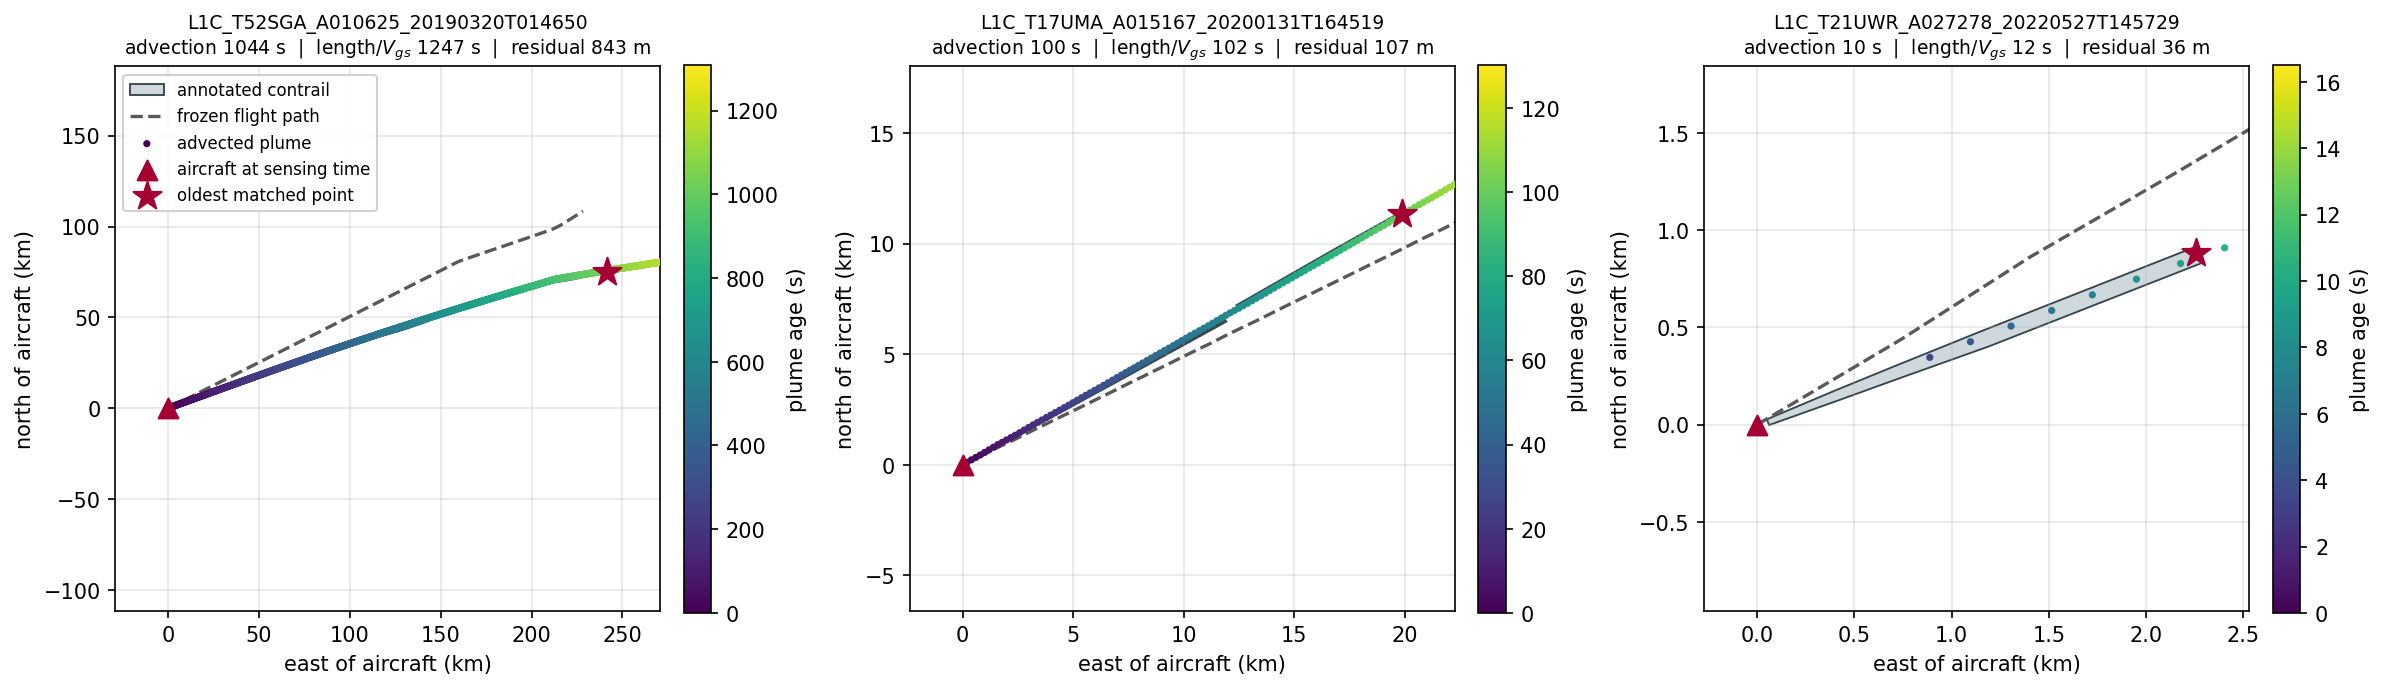

In [15]:
def plot_case(ax, row, margin_frac=0.12):
    """Annotation vs advected plume vs frozen flight path, in image coordinates."""
    res = process_case(row, with_geometry=True)
    g = res["geometry"]
    x0, y0 = g["x_ac"], g["y_ac"]

    def rel(x, y):
        return (np.asarray(x) - x0) / 1e3, (np.asarray(y) - y0) / 1e3

    # only show the part of the plume that is relevant to this annotation
    keep = g["track_age"] <= 1.25 * res["lifetime"] + 5.0
    keep_f = g["frozen_age"] <= 1.25 * res["lifetime"] + 5.0

    tx, ty = rel(g["track_x"][keep], g["track_y"][keep])
    fx, fy = rel(g["frozen_x"][keep_f], g["frozen_y"][keep_f])

    polys = g["geom_utm"].geoms if g["geom_utm"].geom_type == "MultiPolygon" else [g["geom_utm"]]
    for i, poly in enumerate(polys):
        px, py = rel(*poly.exterior.xy)
        ax.fill(px, py, facecolor="#cfd8dc", edgecolor="#37474f", lw=0.9, zorder=1,
                label="annotated contrail" if i == 0 else None)

    ax.plot(fx, fy, color="0.35", ls="--", lw=1.6, zorder=2, label="frozen flight path")
    sc = ax.scatter(tx, ty, c=g["track_age"][keep], cmap="viridis", s=6, zorder=3,
                    label="advected plume")
    ax.scatter([0], [0], marker="^", s=90, color="#a50034", zorder=5,
               label="aircraft at sensing time")
    ox, oy = rel(*g["oldest_xy"])
    ax.scatter([ox], [oy], marker="*", s=200, color="#a50034", zorder=5,
               label="oldest matched point")

    # frame on the annotation, not on the advected track; a square window keeps the
    # equal aspect ratio honest
    bx, by = rel(np.r_[g["boundary"][:, 0], x0], np.r_[g["boundary"][:, 1], y0])
    cx, cy = 0.5 * (bx.min() + bx.max()), 0.5 * (by.min() + by.max())
    half = 0.5 * max(np.ptp(bx), np.ptp(by), 0.5) * (1.0 + 2.0 * margin_frac)
    ax.set_xlim(cx - half, cx + half)
    ax.set_ylim(cy - half, cy + half)

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("east of aircraft (km)")
    ax.set_ylabel("north of aircraft (km)")
    ax.set_title(f"{row['scene_id']}\n"
                 f"advection {res['lifetime']:.0f} s  |  length/$V_{{gs}}$ "
                 f"{res['lifetime_ground_speed']:.0f} s  |  residual "
                 f"{res['mismatch_median_m']:.0f} m", fontsize=9)
    ax.grid(alpha=0.3)
    return sc, res


ranked = results.sort_values("lifetime")
cases = [ranked.index[-1], ranked.index[int(0.9 * len(ranked))], ranked.index[len(ranked) // 2]]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.2), dpi=150)
for ax, scene_id in zip(axes, cases):
    row = df[df["scene_id"] == scene_id].iloc[0]
    sc, _ = plot_case(ax, row)
    fig.colorbar(sc, ax=ax, label="plume age (s)", fraction=0.046, pad=0.04)

axes[0].legend(loc="upper left", fontsize=8, framealpha=0.9)
fig.tight_layout()
plt.savefig("../figures/fig07_dry_advection_cases.png", dpi=300,
            bbox_inches="tight", pad_inches=0.1)
plt.show()

## Does the advected plume actually explain the annotations?

The residual distance between the annotated contrail and the advected plume is the honest
test of the method: if the advection is right the annotation should sit on top of the plume,
and if it is wrong the residual blows up. The *frozen* track (the flight path, anchored and
projected identically) is the control.

In [16]:
summary = pd.DataFrame({
    "advected plume": results["mismatch_median_m"],
    "frozen flight path": results["mismatch_frozen_median_m"],
}).describe(percentiles=[0.5, 0.9, 0.99]).round(0)
print("Median distance between the annotation and the reference track [m]\n")
print(summary.loc[["50%", "90%", "99%", "max"]].to_string())

print("\nQuality flags")
print(f"  annotation points matched within {MATCH_TOL_M:.0f} m : "
      f"median {results['matched_fraction'].median():.3f}, "
      f"min {results['matched_fraction'].min():.3f}")
print(f"  cases that saturate the search window          : {int(results['window_saturated'].sum())}")
print(f"  cases whose oldest point reaches the track end : {int(results['track_end_reached'].sum())}")
print(f"  cases with waypoints outside the ERA5 levels   : {int(results['src_level_outside_era5'].sum())}")
print(f"  cases needing an ERA5 time extrapolation       : {int(results['era5_time_extrapolated'].sum())}")

Median distance between the annotation and the reference track [m]

     advected plume  frozen flight path
50%            36.0                85.0
90%           165.0              1058.0
99%           851.0             10075.0
max          1315.0             18675.0

Quality flags
  annotation points matched within 2000 m : median 1.000, min 0.833
  cases that saturate the search window          : 0
  cases whose oldest point reaches the track end : 0
  cases with waypoints outside the ERA5 levels   : 74
  cases needing an ERA5 time extrapolation       : 8


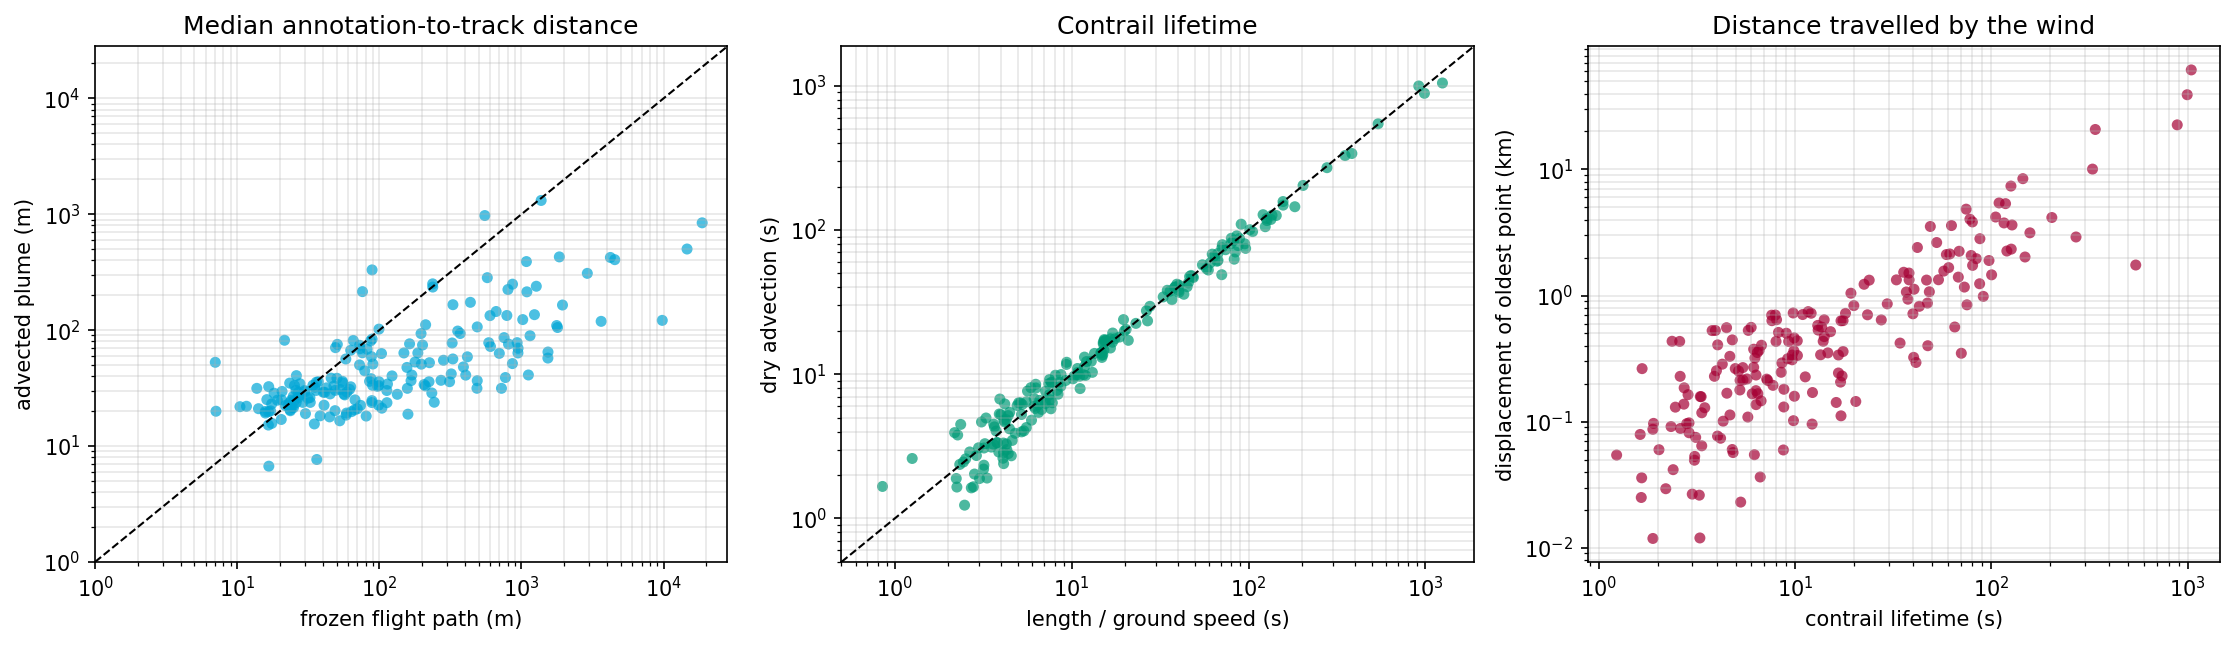

In [17]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4.4), dpi=150)

# (a) residual of the advected plume vs the frozen flight path
lo, hi = 1.0, max(results["mismatch_frozen_median_m"].max(), results["mismatch_median_m"].max()) * 1.5
ax1.scatter(results["mismatch_frozen_median_m"], results["mismatch_median_m"],
            s=28, alpha=0.7, color="#00a6d6", edgecolor="none")
ax1.plot([lo, hi], [lo, hi], "k--", lw=1)
ax1.set_xscale("log"); ax1.set_yscale("log")
ax1.set_xlim(lo, hi); ax1.set_ylim(lo, hi)
ax1.set_xlabel("frozen flight path (m)")
ax1.set_ylabel("advected plume (m)")
ax1.set_title("Median annotation-to-track distance")
ax1.grid(True, which="both", alpha=0.3)

# (b) lifetimes: geometric estimate vs dry advection
lo, hi = 0.5, max(results["lifetime"].max(), results["lifetime_ground_speed"].max()) * 1.5
ax2.scatter(results["lifetime_ground_speed"], results["lifetime"],
            s=28, alpha=0.7, color="#009b77", edgecolor="none")
ax2.plot([lo, hi], [lo, hi], "k--", lw=1)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlim(lo, hi); ax2.set_ylim(lo, hi)
ax2.set_xlabel("length / ground speed (s)")
ax2.set_ylabel("dry advection (s)")
ax2.set_title("Contrail lifetime")
ax2.grid(True, which="both", alpha=0.3)

# (c) how far the wind moved the oldest plume element
ax3.scatter(results["lifetime"], results["advection_displacement_m"] / 1000.0,
            s=28, alpha=0.7, color="#a50034", edgecolor="none")
ax3.set_xscale("log"); ax3.set_yscale("log")
ax3.set_xlabel("contrail lifetime (s)")
ax3.set_ylabel("displacement of oldest point (km)")
ax3.set_title("Distance travelled by the wind")
ax3.grid(True, which="both", alpha=0.3)

fig.tight_layout()
plt.savefig("../figures/fig07_dry_advection_diagnostics.png", dpi=300,
            bbox_inches="tight", pad_inches=0.1)
plt.show()

In [18]:
ratio = (results["lifetime"] / results["lifetime_ground_speed"]).replace([np.inf, -np.inf], np.nan).dropna()
ratio_tas = (results["lifetime"] / results["lifetime_air_speed"]).replace([np.inf, -np.inf], np.nan).dropna()

print("Dry-advection lifetime relative to the geometric estimate")
print(f"  length / ground speed : median {ratio.median():.3f}, "
      f"10-90% {ratio.quantile(0.1):.3f}-{ratio.quantile(0.9):.3f}, "
      f"range {ratio.min():.3f}-{ratio.max():.3f}")
print(f"  length / air speed    : median {ratio_tas.median():.3f}, "
      f"10-90% {ratio_tas.quantile(0.1):.3f}-{ratio_tas.quantile(0.9):.3f}, "
      f"range {ratio_tas.min():.3f}-{ratio_tas.max():.3f}")
print()
print("Under a spatially uniform wind the plume moves with the air, so the aircraft separates")
print("from its own contrail at the *air* speed, not the ground speed. That is why the")
print("air-speed estimate already sits much closer to the Lagrangian answer; what the")
print("advection adds on top is the effect of wind shear and curvature along the plume.")

Dry-advection lifetime relative to the geometric estimate
  length / ground speed : median 0.974, 10-90% 0.754-1.233, range 0.498-2.076
  length / air speed    : median 1.003, 10-90% 0.772-1.257, range 0.543-2.170

Under a spatially uniform wind the plume moves with the air, so the aircraft separates
from its own contrail at the *air* speed, not the ground speed. That is why the
air-speed estimate already sits much closer to the Lagrangian answer; what the
advection adds on top is the effect of wind shear and curvature along the plume.


## Audit of the IAGOS and ERA5 retrieval at the oldest point

The table below quantifies each of the five problems listed above on the actual dataset.

In [19]:
old = pd.read_csv("../data/landsat_sentinel_collocations_20260216_lifetimes_included.csv",
                  comment="#").set_index("scene_id")
has_old = old["lifetime"].notna()
ref = old.loc[has_old]
common = results.index.intersection(ref.index)
cmp = results.loc[common]
ref = ref.loc[common]

print(f"{len(common)} cases in common with figure_7.ipynb\n")

# 1. ERA5 taken at the intersection instead of the oldest point
d_rhi = (cmp["rhi_era5_oldest"] - ref["rhi_era5"]).abs()
print("1. ERA5 humidity: oldest point vs intersection point")
print(f"     |ΔRHi| median {d_rhi.median():.3f}, p90 {d_rhi.quantile(0.9):.3f}, max {d_rhi.max():.3f}")
print(f"     cases where the two straddle ice saturation: "
      f"{int(((cmp['rhi_era5_oldest'] >= 1) != (ref['rhi_era5'] >= 1)).sum())}")

# 2/3. IAGOS guards
print("\n2. IAGOS time index")
print(f"     |t_IAGOS - t_emission| > {IAGOS_TOL_S:.0f} s : {int((results['iagos_dt_s'] > IAGOS_TOL_S).sum())}")
print(f"     emission time outside the IAGOS record      : {int((~results['iagos_in_range']).sum())}")

print("\n3. IAGOS validity flags at the oldest point (0 = good)")
print(f"     air_temp_P1 flag != good : {int((results['iagos_validity_temp'] > IAGOS_GOOD).sum())}")
print(f"     RHL_P1 flag      != good : {int((results['iagos_validity_rhl'] > IAGOS_GOOD).sum())}")
print(f"     cases passing every guard: {int(results['iagos_oldest_valid'].sum())} / {len(results)}")

# 4. engine efficiency
d_eta = (cmp["efficiency_PS_oldest"] - ref["efficiency_PS_IAGOS"]).abs() / ref["efficiency_PS_IAGOS"]
d_dtlc = (cmp["dtlc_iagos_oldest"] - ref["dtlc_iagos_oldest"]).abs()
print("\n4. Engine efficiency at the oldest point vs at the intersection")
print(f"     relative |Δη| median {100 * d_eta.median():.2f}%, max {100 * d_eta.max():.2f}%")
print(f"     resulting |Δ(T_amb - T_LC)| median {d_dtlc.median():.3f} K, max {d_dtlc.max():.3f} K")
print("     (this also contains the change of evaluation point from the advection)")

# 5. the time index itself
d_life = (cmp["lifetime"] - ref["lifetime"]).abs()
print("\n5. Shift of the oldest point caused by the advection")
print(f"     |Δ lifetime| median {d_life.median():.1f} s, p90 {d_life.quantile(0.9):.1f} s, max {d_life.max():.1f} s")
d_T = (cmp["temp_iagos_oldest"] - ref["temp_iagos_oldest"]).abs()
d_rhi_i = (cmp["rhi_iagos_oldest"] - ref["rhi_iagos_oldest"]).abs()
print(f"     resulting |Δ T_IAGOS| median {d_T.median():.2f} K, max {d_T.max():.2f} K")
print(f"     resulting |Δ RHi_IAGOS| median {d_rhi_i.median():.3f}, max {d_rhi_i.max():.3f}")

195 cases in common with figure_7.ipynb

1. ERA5 humidity: oldest point vs intersection point
     |ΔRHi| median 0.002, p90 0.027, max 0.198
     cases where the two straddle ice saturation: 4

2. IAGOS time index
     |t_IAGOS - t_emission| > 10 s : 0
     emission time outside the IAGOS record      : 0

3. IAGOS validity flags at the oldest point (0 = good)
     air_temp_P1 flag != good : 0
     RHL_P1 flag      != good : 0
     cases passing every guard: 195 / 195

4. Engine efficiency at the oldest point vs at the intersection
     relative |Δη| median 0.04%, max 11.59%
     resulting |Δ(T_amb - T_LC)| median 0.011 K, max 2.548 K
     (this also contains the change of evaluation point from the advection)

5. Shift of the oldest point caused by the advection
     |Δ lifetime| median 2.1 s, p90 7.8 s, max 201.0 s
     resulting |Δ T_IAGOS| median 0.00 K, max 3.13 K
     resulting |Δ RHi_IAGOS| median 0.000, max 0.087


In [20]:
# Cross-checks that the retrieval itself is sane.
d_native = (results["rhi_iagos_oldest"] - results["rhi_iagos_oldest_native"]).abs()
print("IAGOS RHi recomputed from RHL (Sonntag/e_sat_ice) vs the archived RHI_P1")
print(f"  |Δ| median {d_native.median():.4f}, p90 {d_native.quantile(0.9):.4f}, max {d_native.max():.4f}")

print("\nERA5 humidity at the oldest point vs along the plume trajectory")
print(f"  RHi at emission        : median {results['rhi_era5_oldest'].median():.3f}")
print(f"  RHi mean over the path : median {results['rhi_era5_traj_mean'].median():.3f}")
print(f"  RHi min  over the path : median {results['rhi_era5_traj_min'].median():.3f}")
print(f"  cases where the path dips below ice saturation although the emission point did not: "
      f"{int(((results['rhi_era5_oldest'] >= 1) & (results['rhi_era5_traj_min'] < 1)).sum())}")

IAGOS RHi recomputed from RHL (Sonntag/e_sat_ice) vs the archived RHI_P1
  |Δ| median 0.0000, p90 0.0001, max 0.0002

ERA5 humidity at the oldest point vs along the plume trajectory
  RHi at emission        : median 0.540
  RHi mean over the path : median 0.540
  RHi min  over the path : median 0.540
  cases where the path dips below ice saturation although the emission point did not: 0


## Figure 7, recreated with the dry-advection lifetimes

Same layout as `figure_7.ipynb`: contrail age against RHi (IAGOS, at the oldest point) and
against $T_{\mathrm{amb}} - T_{\mathrm{LC}}$, with the jet- and vortex-phase reference lines.
Both axes now use quantities evaluated at the *advected* oldest point, with the engine
efficiency taken there as well.

In [21]:
fields = ["rhi_iagos_oldest", "rhi_era5_oldest", "dtlc_iagos_oldest", "lifetime", "out_of_frame"]

data = {key: results[key].to_numpy() for key in fields}

mask = data["lifetime"] > -1
for key in data:
    data[key] = data[key][mask]

rhi_vals       = data["rhi_iagos_oldest"].astype(float)
rhi_era5_vals  = data["rhi_era5_oldest"].astype(float)
dtlc_vals      = data["dtlc_iagos_oldest"].astype(float)
total_age_vals = data["lifetime"].astype(float)
out_of_frame   = data["out_of_frame"].astype(float)

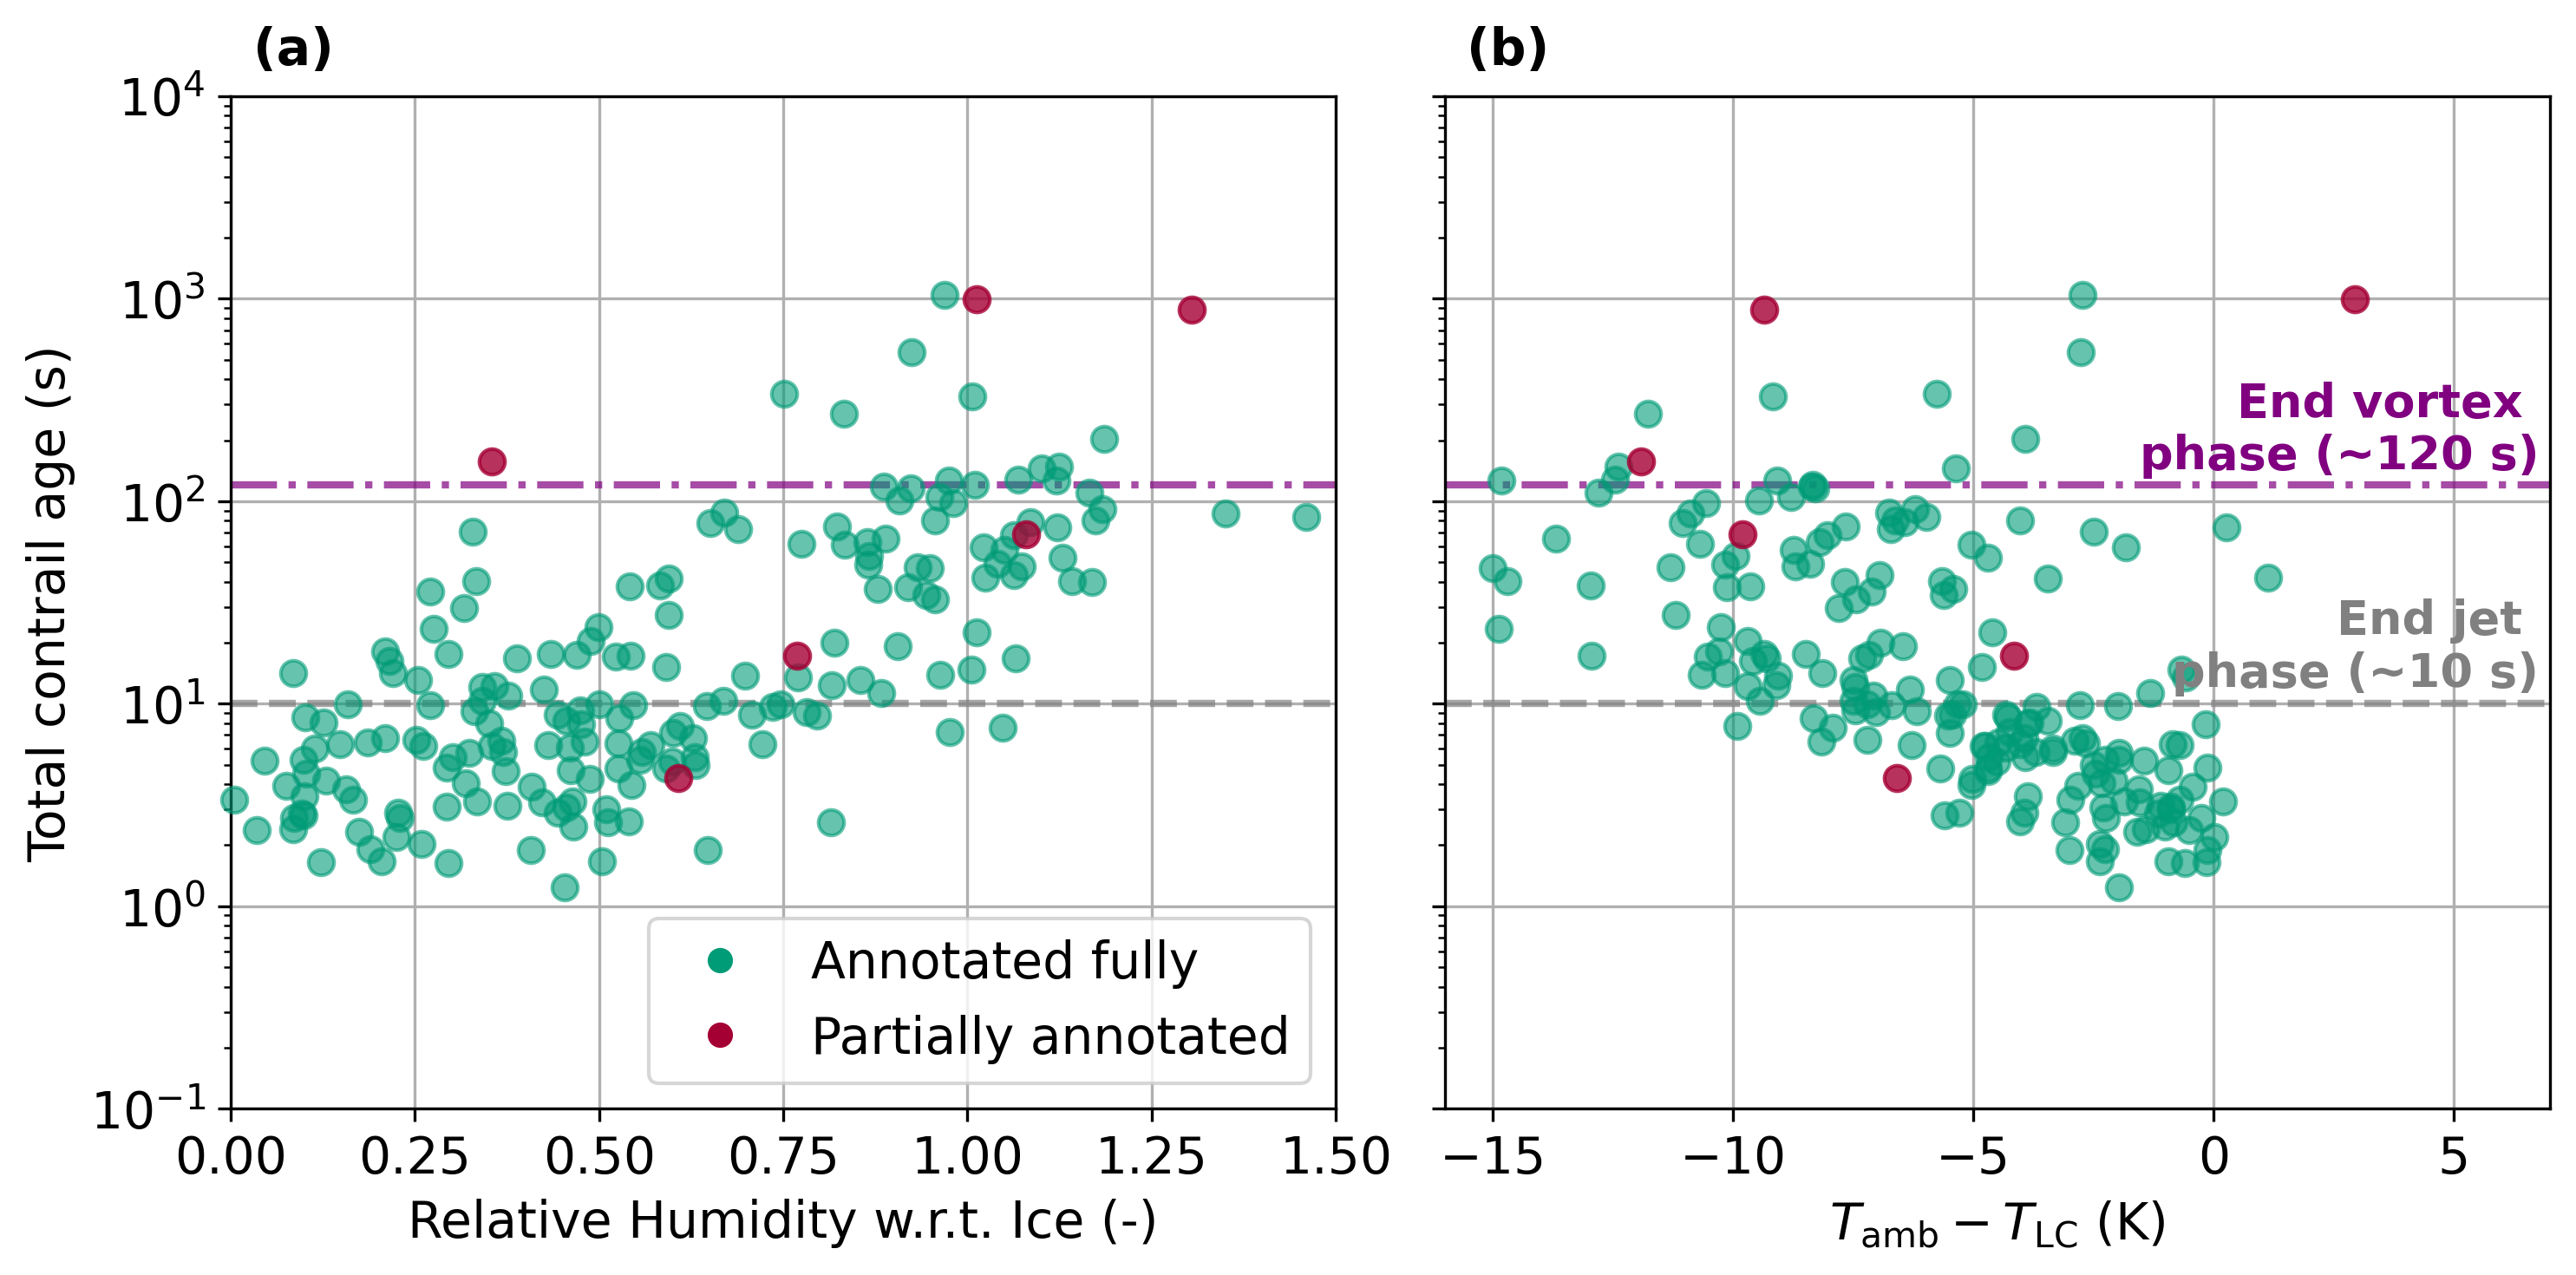

In [22]:
plt.rcParams.update({
    "axes.titlesize": 14,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 14
})

# Masks to plot out_of_frame on top
mask_full = out_of_frame == 0
mask_partial = out_of_frame == 1

cmap = mcolors.ListedColormap(["#009b77", "#a50034"])
norm = mcolors.BoundaryNorm([-0.5, 0.5, 1.5], cmap.N)

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(10, 5), sharey=True, dpi=300
)

# --- Scatter plots ---
ax1.scatter(
    rhi_vals[mask_full],
    total_age_vals[mask_full],
    color="#009b77",
    alpha=0.6,
    s=50,
    zorder=3,
    clip_on=False,
    label="Annotated fully"
)

# Then: partially annotated (on top)
ax1.scatter(
    rhi_vals[mask_partial],
    total_age_vals[mask_partial],
    color="#a50034",
    alpha=0.8,
    s=50,
    zorder=6,  # higher zorder = on top
    clip_on=False,
    label="Partially annotated"
)
ax1.set_xlabel("Relative Humidity w.r.t. Ice (-)")
ax1.set_ylabel("Total contrail age (s)")
ax1.set_yscale("log")
ax1.set_xlim(0, 1.50)
ax1.set_ylim(0.1, 10000)
ax1.grid(True)

ax2.scatter(
    dtlc_vals[mask_full],
    total_age_vals[mask_full],
    color="#009b77",
    alpha=0.6,
    s=50,
    zorder=3,
    clip_on=False
)

ax2.scatter(
    dtlc_vals[mask_partial],
    total_age_vals[mask_partial],
    color="#a50034",
    alpha=0.8,
    s=50,
    zorder=6,
    clip_on=False
)
ax2.set_xlabel(r"$T_{\mathrm{amb}} - T_{\mathrm{LC}}$ (K)")
ax2.set_yscale("log")
ax2.grid(True)
ax2.set_xlim(-16, 7)

# --- Reference lines (no legend) ---
for ax in (ax1, ax2):
    ax.axhline(10, linestyle="--", color="grey", alpha=0.7, linewidth=2)
    ax.axhline(120, linestyle="-.", color="purple", alpha=0.7, linewidth=2)

# Annotations
ax2.text(
    0.99, 11,
    "End jet \nphase (~10 s)",
    color="grey",
    fontsize=13,
    ha="right",
    va="bottom",
    fontweight="bold",
    transform=ax2.get_yaxis_transform()
)

ax2.text(
    0.99, 130,
    "End vortex \nphase (~120 s)",
    color="purple",
    fontsize=13,
    ha="right",
    va="bottom",
    fontweight="bold",
    transform=ax2.get_yaxis_transform()
)

# --- Color legend ---
color_legend = [
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor="#009b77", markersize=8,
           label="Annotated fully"),
    Line2D([0], [0], marker='o', color='white',
           markerfacecolor="#a50034", markersize=8,
           label="Partially annotated")
]

ax1.legend(handles=color_legend, loc="lower right")

# --- Panel labels ---
ax1.text(
    0.02, 1.07, "(a)",
    transform=ax1.transAxes,
    fontsize=14,
    fontweight="bold",
    va="top",
    ha="left"
)

ax2.text(
    0.02, 1.07, "(b)",
    transform=ax2.transAxes,
    fontsize=14,
    fontweight="bold",
    va="top",
    ha="left"
)

fig.tight_layout()
plt.savefig("../figures/fig07_dry_advection.png", dpi=300, bbox_inches='tight', pad_inches=0.1)
plt.show()

## Statistics on contrail lifetimes

In [23]:
print(f"Pecentage of flights surviving above 10(s): {round(sum([1 for age in total_age_vals if age >= 10]) / len(total_age_vals), 3)}% ({sum([1 for age in total_age_vals if age >= 10])} cases)")
print(f"Pecentage of flights surviving above 120(s): {round(sum([1 for age in total_age_vals if age >= 120]) / len(total_age_vals), 3)}% ({sum([1 for age in total_age_vals if age >= 120])} cases)")

Pecentage of flights surviving above 10(s): 0.492% (96 cases)
Pecentage of flights surviving above 120(s): 0.077% (15 cases)


In [24]:
# ensure arrays are 1D
age = np.array(total_age_vals).ravel()
rhi = np.array(rhi_era5_vals).ravel()

# valid data (remove NaNs)
mask = (~np.isnan(age)) & (~np.isnan(rhi))
age = age[mask]
rhi = rhi[mask]

def stats_for_range(min_age, max_age):
    if max_age is None:
        sel = age > min_age
    else:
        sel = (age >= min_age) & (age < max_age)

    mean_rhi = rhi[sel].mean()
    std_rhi = rhi[sel].std(ddof=1)  # sample standard deviation
    count = sel.sum()

    return mean_rhi, std_rhi, count

ranges = [
    ("0-10 s", 0, 10),
    ("10-120 s", 10, 120),
    (">120 s", 120, None)
]

for label, mn, mx in ranges:
    mean_rhi, std_rhi, count = stats_for_range(mn, mx)
    print(f"{label}: n={count}, mean RHi={mean_rhi:.3f}, std RHi={std_rhi:.3f}")

0-10 s: n=99, mean RHi=0.394, std RHi=0.236
10-120 s: n=81, mean RHi=0.736, std RHi=0.273
>120 s: n=15, mean RHi=0.964, std RHi=0.165


In [25]:
def report_r2(x_vals, y_vals, name):
    m = (~np.isnan(x_vals)) & (~np.isnan(y_vals)) & (y_vals > 0)
    x = x_vals[m].reshape(-1, 1)
    y = y_vals[m]

    r2 = LinearRegression().fit(x, y).score(x, y)
    r2_log = LinearRegression().fit(x, np.log(y)).score(x, np.log(y))
    print(f"R² ({name} vs age): {r2:.4f}    R² ({name} vs log(age)): {r2_log:.4f}")

report_r2(rhi_vals, total_age_vals, "rhi iagos")
report_r2(rhi_era5_vals, total_age_vals, "rhi era5")
report_r2(results["rhi_era5_traj_mean"].to_numpy(dtype=float), total_age_vals, "rhi era5 traj-mean")
report_r2(results["rhi_era5_traj_min"].to_numpy(dtype=float), total_age_vals, "rhi era5 traj-min")
report_r2(dtlc_vals.reshape(-1), total_age_vals, "dtlc")

R² (rhi iagos vs age): 0.1448    R² (rhi iagos vs log(age)): 0.5024
R² (rhi era5 vs age): 0.1290    R² (rhi era5 vs log(age)): 0.4780
R² (rhi era5 traj-mean vs age): 0.1286    R² (rhi era5 traj-mean vs log(age)): 0.4772
R² (rhi era5 traj-min vs age): 0.1248    R² (rhi era5 traj-min vs log(age)): 0.4728
R² (dtlc vs age): 0.0032    R² (dtlc vs log(age)): 0.2841


## Contrail lifetime as a function of RHi and temperature

Same "Observation" panel as in `figure_7.ipynb`, now binned on the IAGOS RHi and temperature
at the *advected* oldest point. Bins backed by a single observation are hatched.

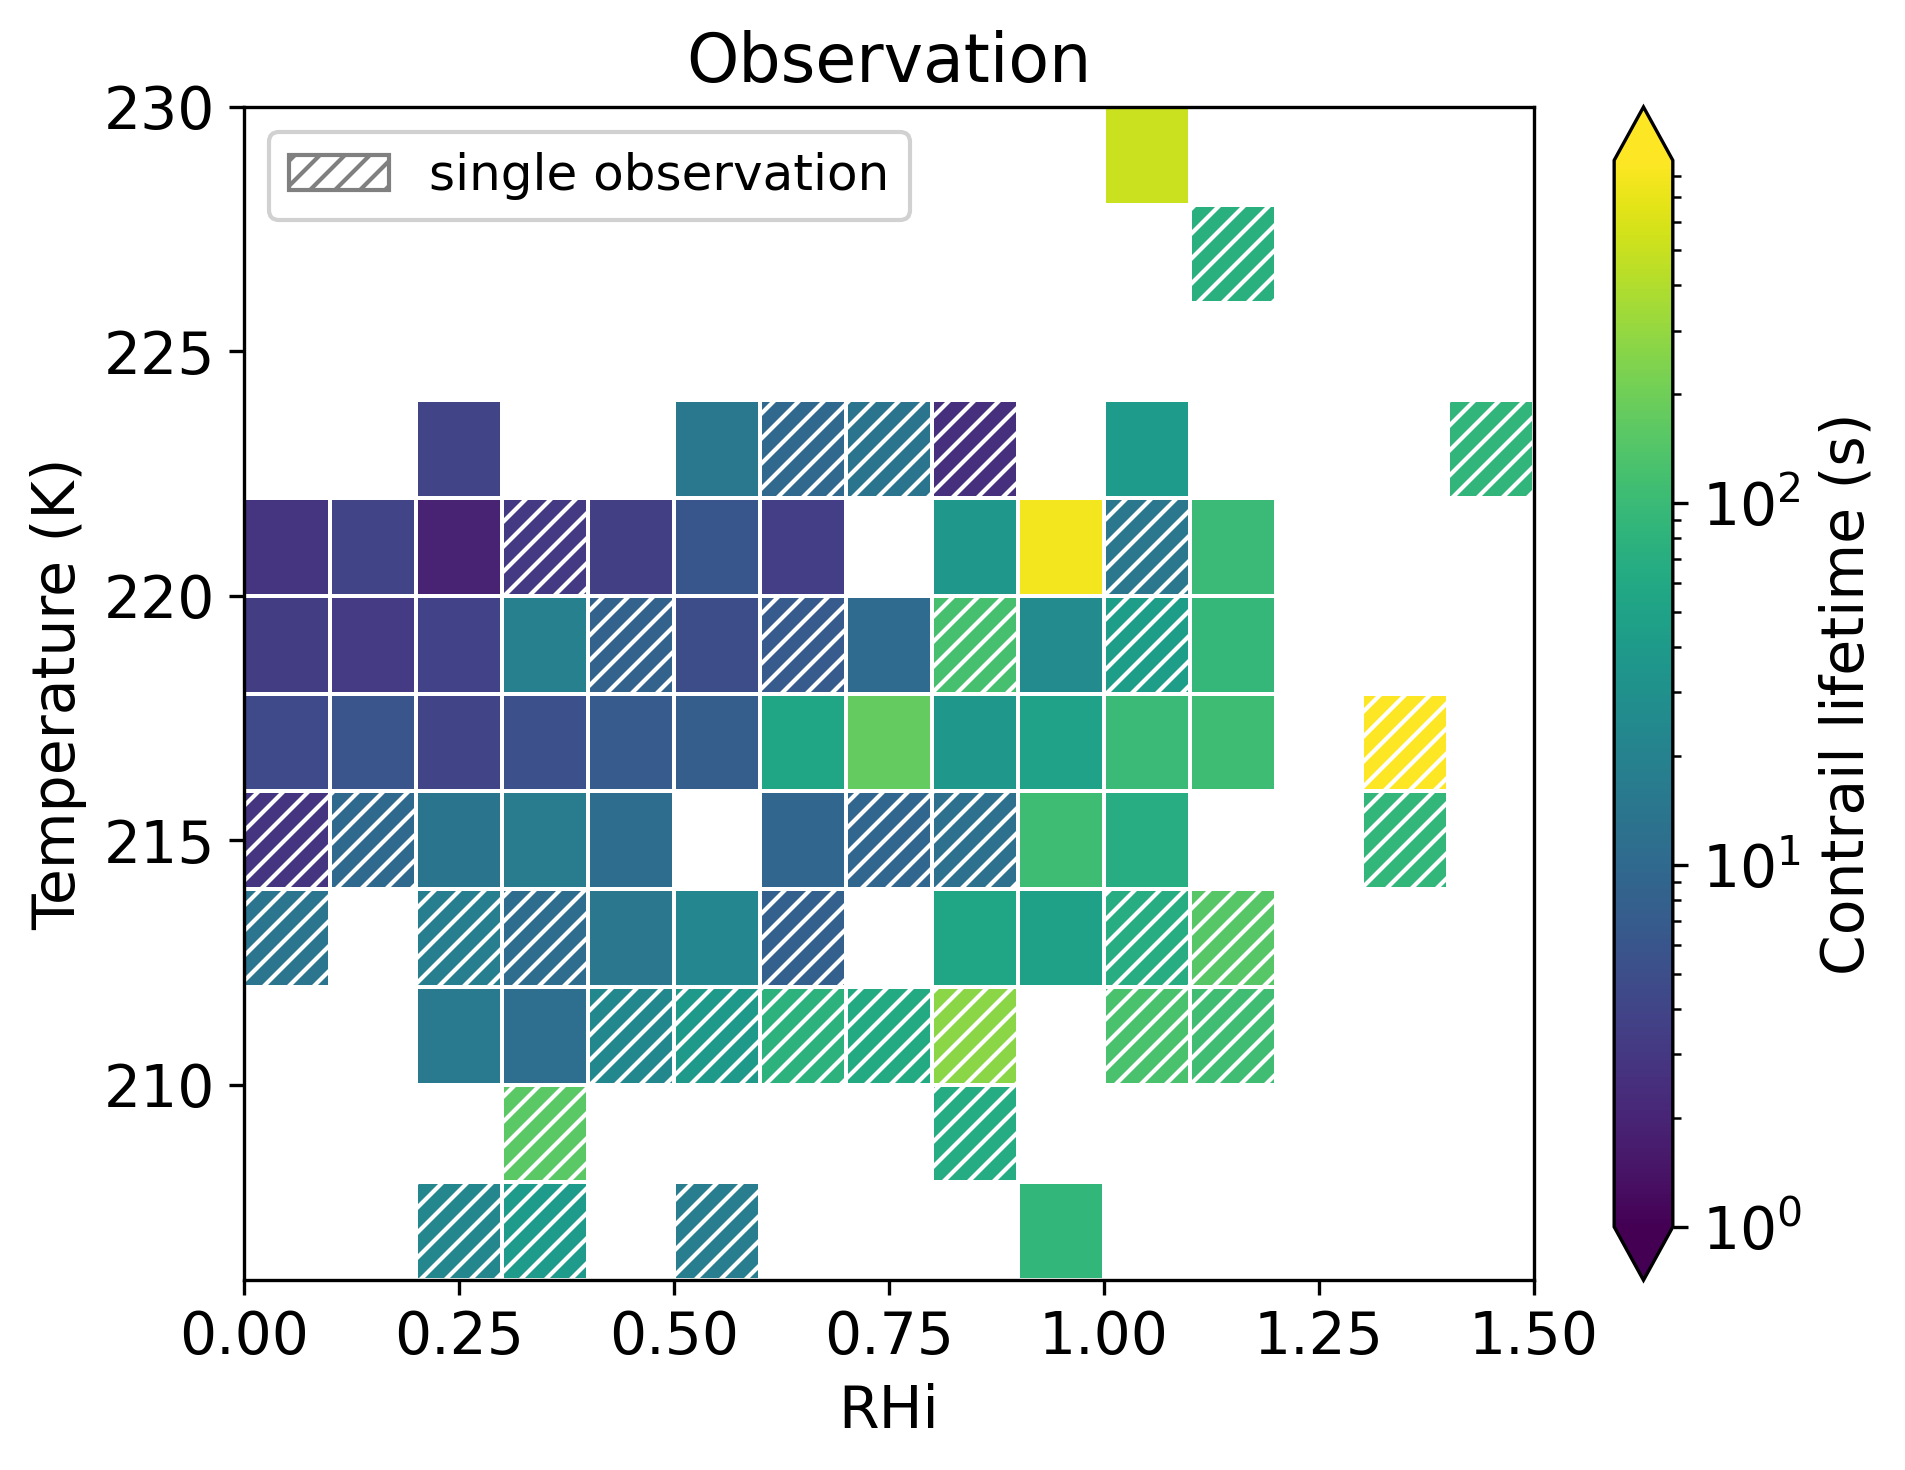

In [26]:
df_life = results.dropna(subset=["lifetime", "temp_iagos_oldest", "rhi_iagos_oldest"])

rhi  = df_life["rhi_iagos_oldest"].to_numpy(dtype=float)
temp = df_life["temp_iagos_oldest"].to_numpy(dtype=float)
life = df_life["lifetime"].to_numpy(dtype=float)

# Bin edges in RHi (x) and temperature (y)
rhi_edges  = np.arange(0.0, 1.5 + 1e-9, 0.1)
temp_edges = np.arange(206, 230 + 1e-9, 2.0)

# Mean lifetime and sample count per bin
sum_life, _, _ = np.histogram2d(rhi, temp, bins=[rhi_edges, temp_edges], weights=life)
count, _, _    = np.histogram2d(rhi, temp, bins=[rhi_edges, temp_edges])
with np.errstate(invalid="ignore"):
    mean_life = sum_life / count
mean_life[count == 0] = np.nan

# Transpose so rows = temperature (y), cols = RHi (x) for pcolormesh
mean_life = mean_life.T
count = count.T

plt.rcParams.update({
    "axes.titlesize": 16,
    "axes.labelsize": 14,
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,
    "legend.fontsize": 12,
})

fig, ax = plt.subplots(figsize=(6.5, 5), dpi=300)

norm = mcolors.LogNorm(vmin=1.0, vmax=np.nanmax(mean_life))
pcm = ax.pcolormesh(
    rhi_edges, temp_edges, np.ma.masked_invalid(mean_life),
    cmap="viridis", norm=norm, shading="flat",
    edgecolors="white", linewidth=0.5,
)

# Hatch bins backed by a single observation to flag low confidence
sparse = count == 1
for i in range(count.shape[0]):
    for j in range(count.shape[1]):
        if sparse[i, j]:
            ax.add_patch(plt.Rectangle(
                (rhi_edges[j], temp_edges[i]),
                rhi_edges[j + 1] - rhi_edges[j],
                temp_edges[i + 1] - temp_edges[i],
                facecolor="none", edgecolor="white", hatch="////", linewidth=0.0,
            ))

ax.set_xlabel("RHi")
ax.set_ylabel("Temperature (K)")
ax.set_title("Observation")
ax.set_xlim(rhi_edges[0], rhi_edges[-1])
ax.set_ylim(temp_edges[0], temp_edges[-1])

hatch_legend = [Patch(facecolor="white", edgecolor="grey", hatch="////",
                      label="single observation")]
ax.legend(handles=hatch_legend, loc="upper left", framealpha=0.9)

cbar = fig.colorbar(pcm, ax=ax, extend="both")
cbar.set_label("Contrail lifetime (s)")

fig.tight_layout()
plt.savefig("../figures/fig07_temp_rhi_lifetime_dry_advection.png", dpi=300,
            bbox_inches="tight", pad_inches=0.1)
plt.show()

## Temperature, the IAGOS humidity uncertainty, and the persistent sub-saturated contrails

Figure 7(a) contains points that should not exist: contrails that survive well past the vortex
phase in air that IAGOS reports as sub-saturated with respect to ice. A contrail cannot persist
at $\mathrm{RHi} < 1$, so either the lifetime, the humidity, or the assumption that a single
point represents the whole contrail is wrong.

The IAGOS humidity sensor is the obvious suspect. It is a capacitive sensor calibrated against
a frost-point reference, and its quoted uncertainty grows as the air gets colder and drier.
Crucially, the archived $\mathrm{RHi}$ uncertainty is the $\mathrm{RHL}$ uncertainty scaled by
$e_{\mathrm{sat,liq}}/e_{\mathrm{sat,ice}}$, and that ratio itself grows as temperature falls,
so $\sigma_{\mathrm{RHi}}$ steepens twice over with decreasing $T$.

Three things are added below, each of which the dataset already contains but `figure_7.ipynb`
never used:

1. the **ambient temperature** at the oldest point, as an axis and as a colour;
2. the **IAGOS 1$\sigma$ uncertainties** (`RHI_P1_error`, `RHL_P1_error`, `air_temp_P1_error`)
   at the oldest point;
3. the **range of RHi measured along the whole contrail-forming segment** — the contrail was
   laid down between the oldest point and the aircraft, and IAGOS sampled that entire stretch,
   so the single-point value is not the only humidity the contrail ever saw.

In [27]:
PERSISTENT_S = 120.0   # end of the vortex phase: a contrail older than this must be persisting
JET_S = 10.0           # end of the jet phase

res = results.copy()
res["rhi_sigma"] = res["rhi_iagos_oldest_error"]
res["z_saturation"] = (res["rhi_iagos_oldest"] - 1.0) / res["rhi_sigma"]

persistent = res[res["lifetime"] >= PERSISTENT_S]
beyond_jet = res[res["lifetime"] >= JET_S]

print(f"IAGOS 1-sigma uncertainty at the oldest point over all {len(res)} cases")
print(f"  sigma(RHi) : median {res['rhi_sigma'].median():.3f}, "
      f"10-90% {res['rhi_sigma'].quantile(0.1):.3f}-{res['rhi_sigma'].quantile(0.9):.3f}, "
      f"max {res['rhi_sigma'].max():.3f}")
print(f"  sigma(RHL) : median {res['rhl_iagos_oldest_error'].median():.3f}")
print(f"  sigma(T)   : median {res['temp_iagos_oldest_error'].median():.2f} K")

edges = np.arange(206, 232, 4.0)
binned = (
    res.assign(Tbin=pd.cut(res["temp_iagos_oldest"], edges))
       .groupby("Tbin", observed=True)
       .agg(n=("rhi_sigma", "size"),
            sigma_rhi=("rhi_sigma", "median"),
            sigma_rhl=("rhl_iagos_oldest_error", "median"),
            rhi=("rhi_iagos_oldest", "median"))
       .round(3)
)
print("\nUncertainty against temperature (medians per 4 K bin)")
print(binned.to_string())
print(f"\nSpearman rank correlation sigma(RHi) vs T : "
      f"{res[['rhi_sigma', 'temp_iagos_oldest']].corr(method='spearman').iloc[0, 1]:+.3f}")
print(f"Spearman rank correlation sigma(RHL) vs T : "
      f"{res[['rhl_iagos_oldest_error', 'temp_iagos_oldest']].corr(method='spearman').iloc[0, 1]:+.3f}")

IAGOS 1-sigma uncertainty at the oldest point over all 195 cases
  sigma(RHi) : median 0.121, 10-90% 0.098-0.149, max 0.256
  sigma(RHL) : median 0.070
  sigma(T)   : median 0.42 K

Uncertainty against temperature (medians per 4 K bin)
                 n  sigma_rhi  sigma_rhl    rhi
Tbin                                           
(206.0, 210.0]   7      0.168      0.089  0.542
(210.0, 214.0]  33      0.133      0.073  0.594
(214.0, 218.0]  73      0.121      0.070  0.501
(218.0, 222.0]  68      0.115      0.068  0.470
(222.0, 226.0]  11      0.103      0.063  0.647
(226.0, 230.0]   3      0.100      0.064  1.024

Spearman rank correlation sigma(RHi) vs T : -0.549
Spearman rank correlation sigma(RHL) vs T : -0.387


### Contrail lifetime against temperature

Panel (a) is the missing third axis of figure 7: lifetime against the ambient temperature at
the oldest point, coloured by RHi. Panel (b) is figure 7(a) recoloured by temperature, which is
where the sub-saturated survivors give themselves away.

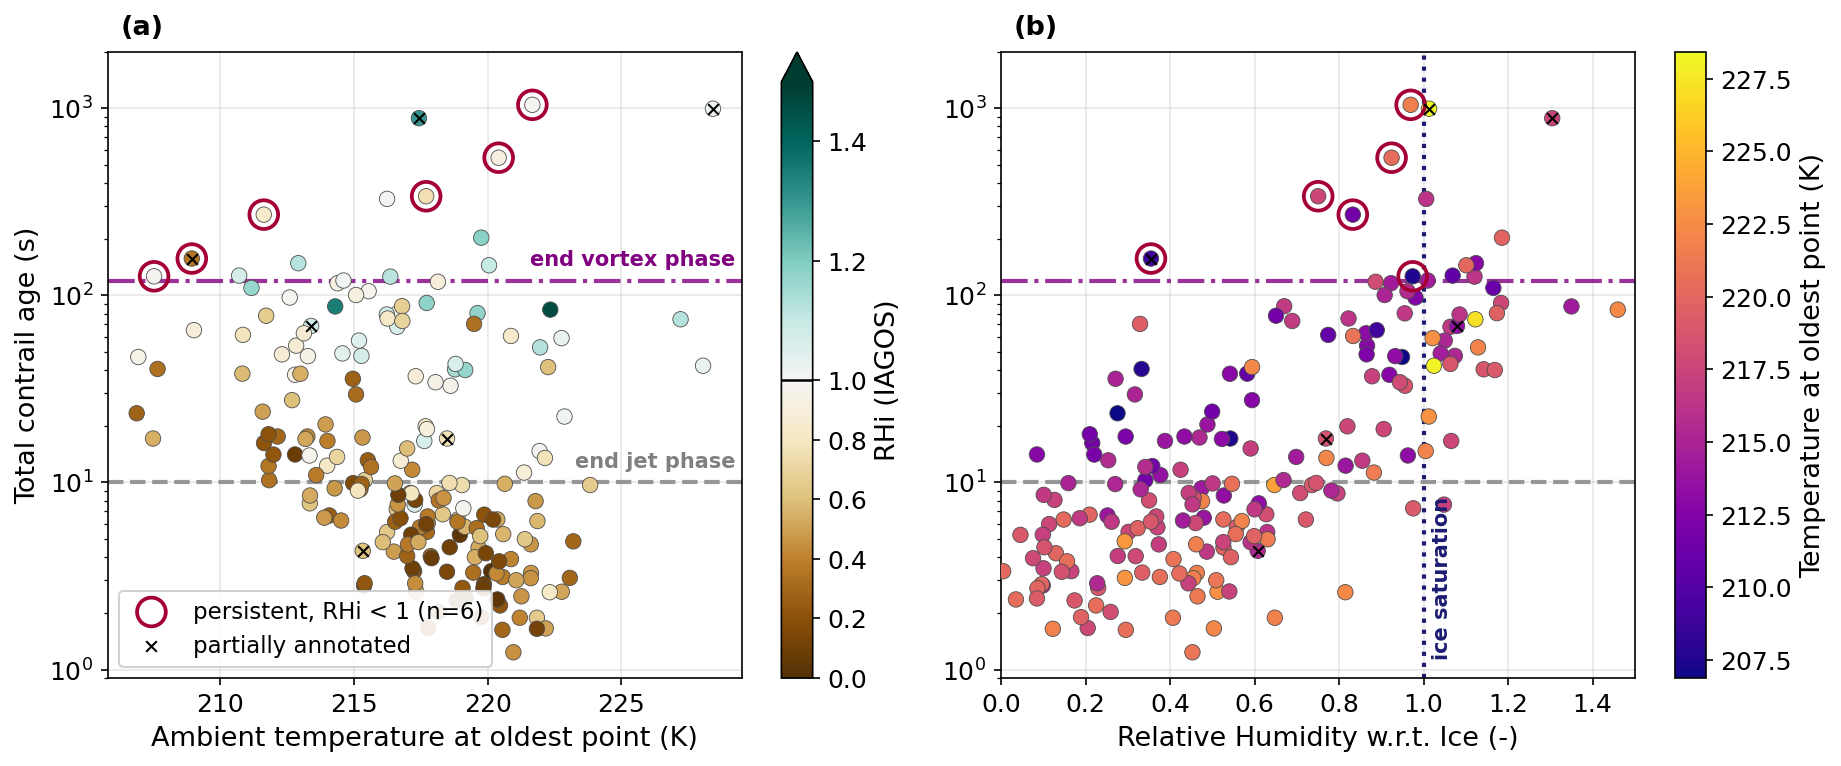

In [28]:
plt.rcParams.update({
    "axes.titlesize": 13, "axes.labelsize": 13,
    "xtick.labelsize": 12, "ytick.labelsize": 12, "legend.fontsize": 11,
})

life = res["lifetime"].to_numpy(dtype=float)
temp = res["temp_iagos_oldest"].to_numpy(dtype=float)
rhi = res["rhi_iagos_oldest"].to_numpy(dtype=float)
sig = res["rhi_sigma"].to_numpy(dtype=float)
oof = res["out_of_frame"].to_numpy(dtype=float) == 1

# a contrail older than the vortex phase must be persisting, so it should sit at RHi >= 1
suspect = (life >= PERSISTENT_S) & (rhi < 1.0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.2), dpi=150)

# (a) lifetime vs temperature, coloured by RHi (diverging about ice saturation)
norm_rhi = mcolors.TwoSlopeNorm(vmin=0.0, vcenter=1.0, vmax=1.5)
sc1 = ax1.scatter(temp, life, c=rhi, cmap="BrBG", norm=norm_rhi,
                  s=55, edgecolor="0.3", linewidth=0.4, zorder=3)
ax1.scatter(temp[suspect], life[suspect], facecolor="none", edgecolor="#a50034",
            s=190, linewidth=1.8, zorder=4,
            label=f"persistent, RHi < 1 (n={int(suspect.sum())})")
ax1.scatter(temp[oof], life[oof], marker="x", color="k", s=26, linewidth=1.0,
            zorder=5, label="partially annotated")
ax1.set_yscale("log")
ax1.set_xlabel("Ambient temperature at oldest point (K)")
ax1.set_ylabel("Total contrail age (s)")
cb1 = fig.colorbar(sc1, ax=ax1, extend="max")
cb1.set_label("RHi (IAGOS)")
cb1.ax.axhline(1.0, color="k", lw=1.2)

# (b) figure 7(a), recoloured by temperature
sc2 = ax2.scatter(rhi, life, c=temp, cmap="plasma", s=55,
                  edgecolor="0.3", linewidth=0.4, zorder=3)
ax2.scatter(rhi[suspect], life[suspect], facecolor="none", edgecolor="#a50034",
            s=190, linewidth=1.8, zorder=4)
ax2.scatter(rhi[oof], life[oof], marker="x", color="k", s=26, linewidth=1.0, zorder=5)
ax2.axvline(1.0, color="#1c1c73", lw=2, ls=":", zorder=2)
ax2.text(1.02, 0.03, "ice saturation", rotation=90, color="#1c1c73",
         fontsize=10, fontweight="bold", va="bottom", ha="left",
         transform=ax2.get_xaxis_transform())
ax2.set_yscale("log")
ax2.set_xlim(0, 1.5)
ax2.set_xlabel("Relative Humidity w.r.t. Ice (-)")
cb2 = fig.colorbar(sc2, ax=ax2)
cb2.set_label("Temperature at oldest point (K)")

for ax, lab in ((ax1, "(a)"), (ax2, "(b)")):
    ax.set_ylim(0.9, 2000)
    ax.grid(True, alpha=0.3)
    ax.axhline(JET_S, ls="--", color="grey", alpha=0.8, lw=2)
    ax.axhline(PERSISTENT_S, ls="-.", color="purple", alpha=0.8, lw=2)
    ax.text(0.02, 1.06, lab, transform=ax.transAxes, fontsize=13,
            fontweight="bold", va="top", ha="left")

ax1.text(0.99, JET_S * 1.15, "end jet phase", color="grey", fontsize=10, ha="right",
         va="bottom", fontweight="bold", transform=ax1.get_yaxis_transform())
ax1.text(0.99, PERSISTENT_S * 1.15, "end vortex phase", color="purple", fontsize=10,
         ha="right", va="bottom", fontweight="bold", transform=ax1.get_yaxis_transform())
ax1.legend(loc="lower left", framealpha=0.9)

fig.tight_layout()
plt.savefig("../figures/fig07_lifetime_temperature.png", dpi=300,
            bbox_inches="tight", pad_inches=0.1)
plt.show()

### How large is the humidity uncertainty, and does it cover the gap?

Panel (a) shows the IAGOS 1$\sigma$ uncertainty against temperature. Panel (b) repeats figure
7(a) with that uncertainty drawn on every point. Panel (c) converts the picture into a single
number per case,

$$ z = \frac{\mathrm{RHi} - 1}{\sigma_{\mathrm{RHi}}}, $$

the number of standard deviations between the measurement and ice saturation. A persistent
contrail with $z < -2$ is genuinely hard to explain; one with $-2 < z < 0$ is statistically
compatible with having formed in saturated air.

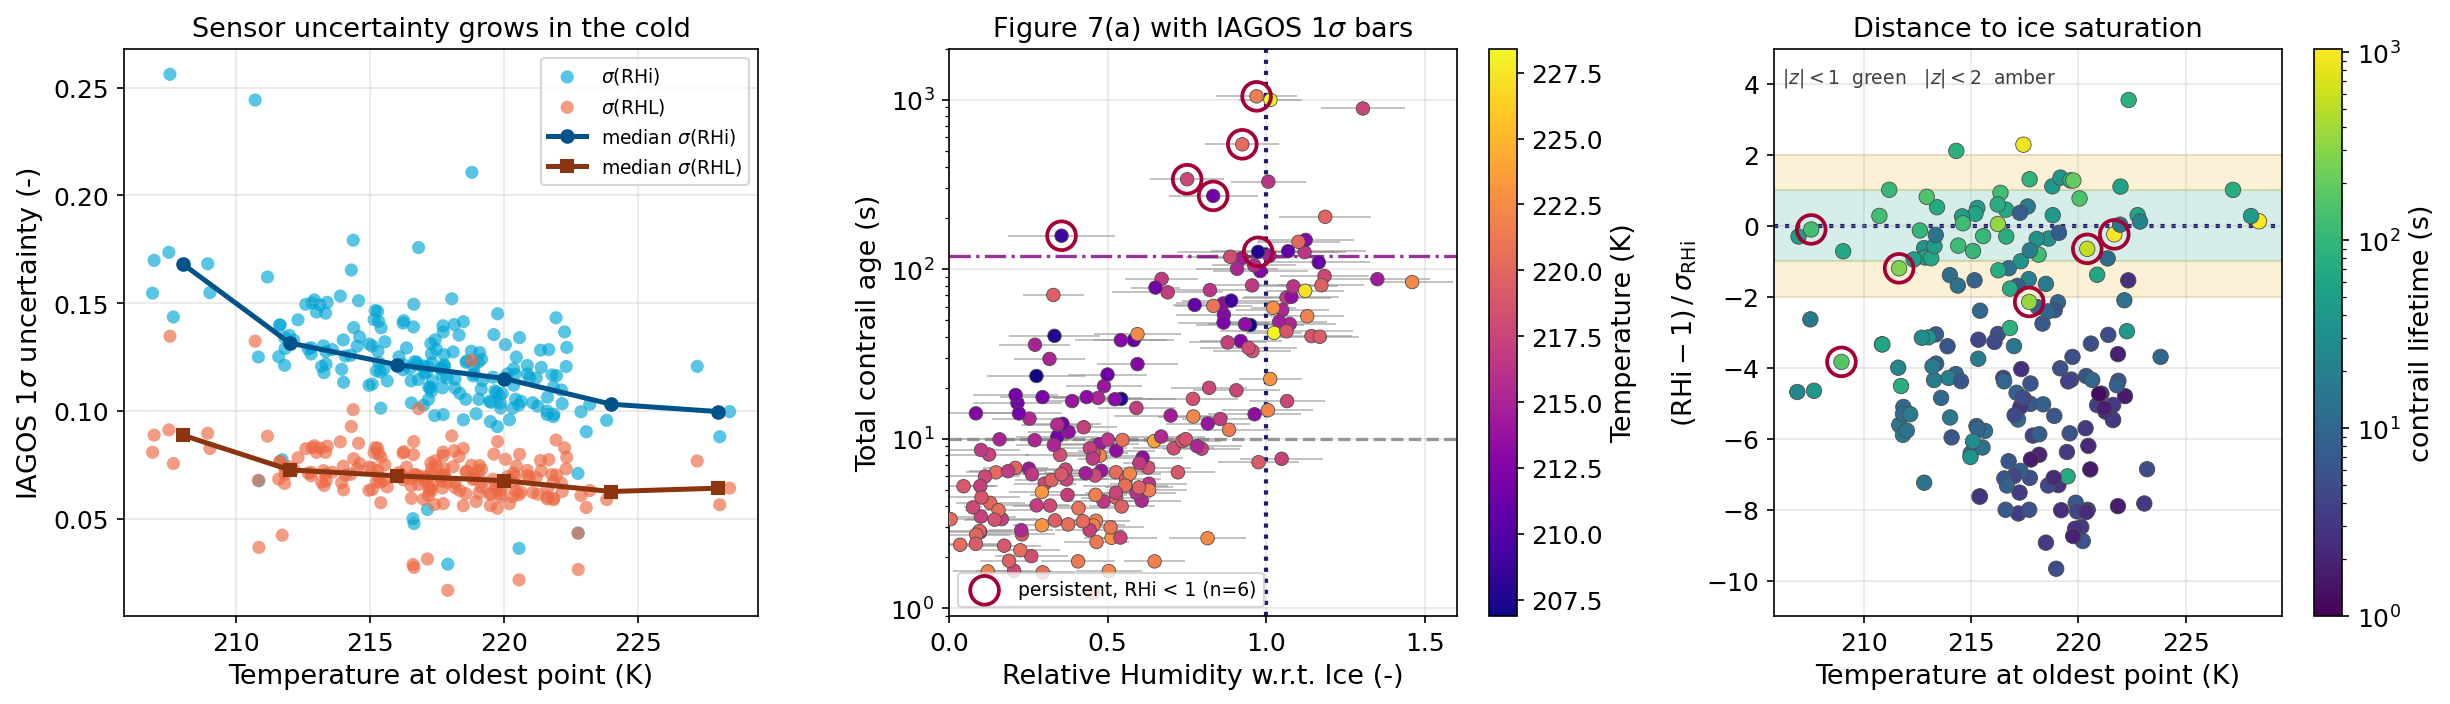

In [29]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(16.5, 4.8), dpi=150)

# --- (a) the uncertainty itself, against temperature --------------------------------
ax1.scatter(temp, sig, s=40, color="#00a6d6", alpha=0.65, edgecolor="none",
            label=r"$\sigma$(RHi)")
ax1.scatter(temp, res["rhl_iagos_oldest_error"], s=40, color="#ec6842", alpha=0.65,
            edgecolor="none", label=r"$\sigma$(RHL)")

centres = 0.5 * (edges[:-1] + edges[1:])
med_rhi = [res.loc[(temp >= lo) & (temp < hi), "rhi_sigma"].median()
           for lo, hi in zip(edges[:-1], edges[1:])]
med_rhl = [res.loc[(temp >= lo) & (temp < hi), "rhl_iagos_oldest_error"].median()
           for lo, hi in zip(edges[:-1], edges[1:])]
ax1.plot(centres, med_rhi, color="#00538a", lw=2.4, marker="o", zorder=5,
         label=r"median $\sigma$(RHi)")
ax1.plot(centres, med_rhl, color="#8a3410", lw=2.4, marker="s", zorder=5,
         label=r"median $\sigma$(RHL)")

ax1.set_xlabel("Temperature at oldest point (K)")
ax1.set_ylabel(r"IAGOS 1$\sigma$ uncertainty (-)")
ax1.set_title("Sensor uncertainty grows in the cold")
ax1.grid(alpha=0.3)
ax1.legend(loc="upper right", fontsize=9)

# --- (b) figure 7(a) with the uncertainty drawn on ----------------------------------
ax2.errorbar(rhi, life, xerr=sig, fmt="none", ecolor="0.55",
             elinewidth=0.9, capsize=0, alpha=0.55, zorder=2)
sc = ax2.scatter(rhi, life, c=temp, cmap="plasma", s=42,
                 edgecolor="0.3", linewidth=0.4, zorder=3)
flag = (life >= PERSISTENT_S) & (rhi < 1.0)
ax2.scatter(rhi[flag], life[flag], facecolor="none", edgecolor="#a50034",
            s=190, linewidth=1.8, zorder=4,
            label=f"persistent, RHi < 1 (n={int(flag.sum())})")
ax2.axvline(1.0, color="#1c1c73", lw=2, ls=":", zorder=2)
ax2.axhline(JET_S, ls="--", color="grey", alpha=0.8, lw=1.6)
ax2.axhline(PERSISTENT_S, ls="-.", color="purple", alpha=0.8, lw=1.6)
ax2.set_yscale("log")
ax2.set_xlim(0, 1.6)
ax2.set_ylim(0.9, 2000)
ax2.set_xlabel("Relative Humidity w.r.t. Ice (-)")
ax2.set_ylabel("Total contrail age (s)")
ax2.set_title(r"Figure 7(a) with IAGOS 1$\sigma$ bars")
ax2.grid(alpha=0.3)
ax2.legend(loc="lower left", fontsize=9)
fig.colorbar(sc, ax=ax2, label="Temperature (K)")

# --- (c) distance to saturation in standard deviations ------------------------------
z = res["z_saturation"].to_numpy(dtype=float)
ax3.axhspan(-1, 1, color="#009b77", alpha=0.16, zorder=0)
ax3.axhspan(-2, -1, color="#f0b323", alpha=0.18, zorder=0)
ax3.axhspan(1, 2, color="#f0b323", alpha=0.18, zorder=0)
ax3.axhline(0, color="#1c1c73", lw=2, ls=":", zorder=1)

sc3 = ax3.scatter(temp, z, c=life, cmap="viridis", norm=mcolors.LogNorm(vmin=1, vmax=life.max()),
                  s=55, edgecolor="0.3", linewidth=0.4, zorder=3)
ax3.scatter(temp[flag], z[flag], facecolor="none", edgecolor="#a50034",
            s=190, linewidth=1.8, zorder=4)
ax3.set_xlabel("Temperature at oldest point (K)")
ax3.set_ylabel(r"$(\mathrm{RHi}-1)\,/\,\sigma_{\mathrm{RHi}}$")
ax3.set_title("Distance to ice saturation")
ax3.set_ylim(-11, 5)
ax3.grid(alpha=0.3)
ax3.text(0.015, 0.97, r"$|z|<1$  green   $|z|<2$  amber", transform=ax3.transAxes,
         fontsize=9, va="top", color="0.25")
fig.colorbar(sc3, ax=ax3, label="contrail lifetime (s)")

fig.tight_layout()
plt.savefig("../figures/fig07_rhi_uncertainty.png", dpi=300,
            bbox_inches="tight", pad_inches=0.1)
plt.show()

### The persistent sub-saturated contrails, one by one

Every contrail that outlived the vortex phase is shown below with everything the dataset knows
about its humidity: the IAGOS value at the oldest point with its 1$\sigma$ and 2$\sigma$ bars,
the full range of RHi that IAGOS measured **along the contrail-forming segment**, and the ERA5
value at the same point. A case is only genuinely anomalous if none of these reaches ice
saturation.

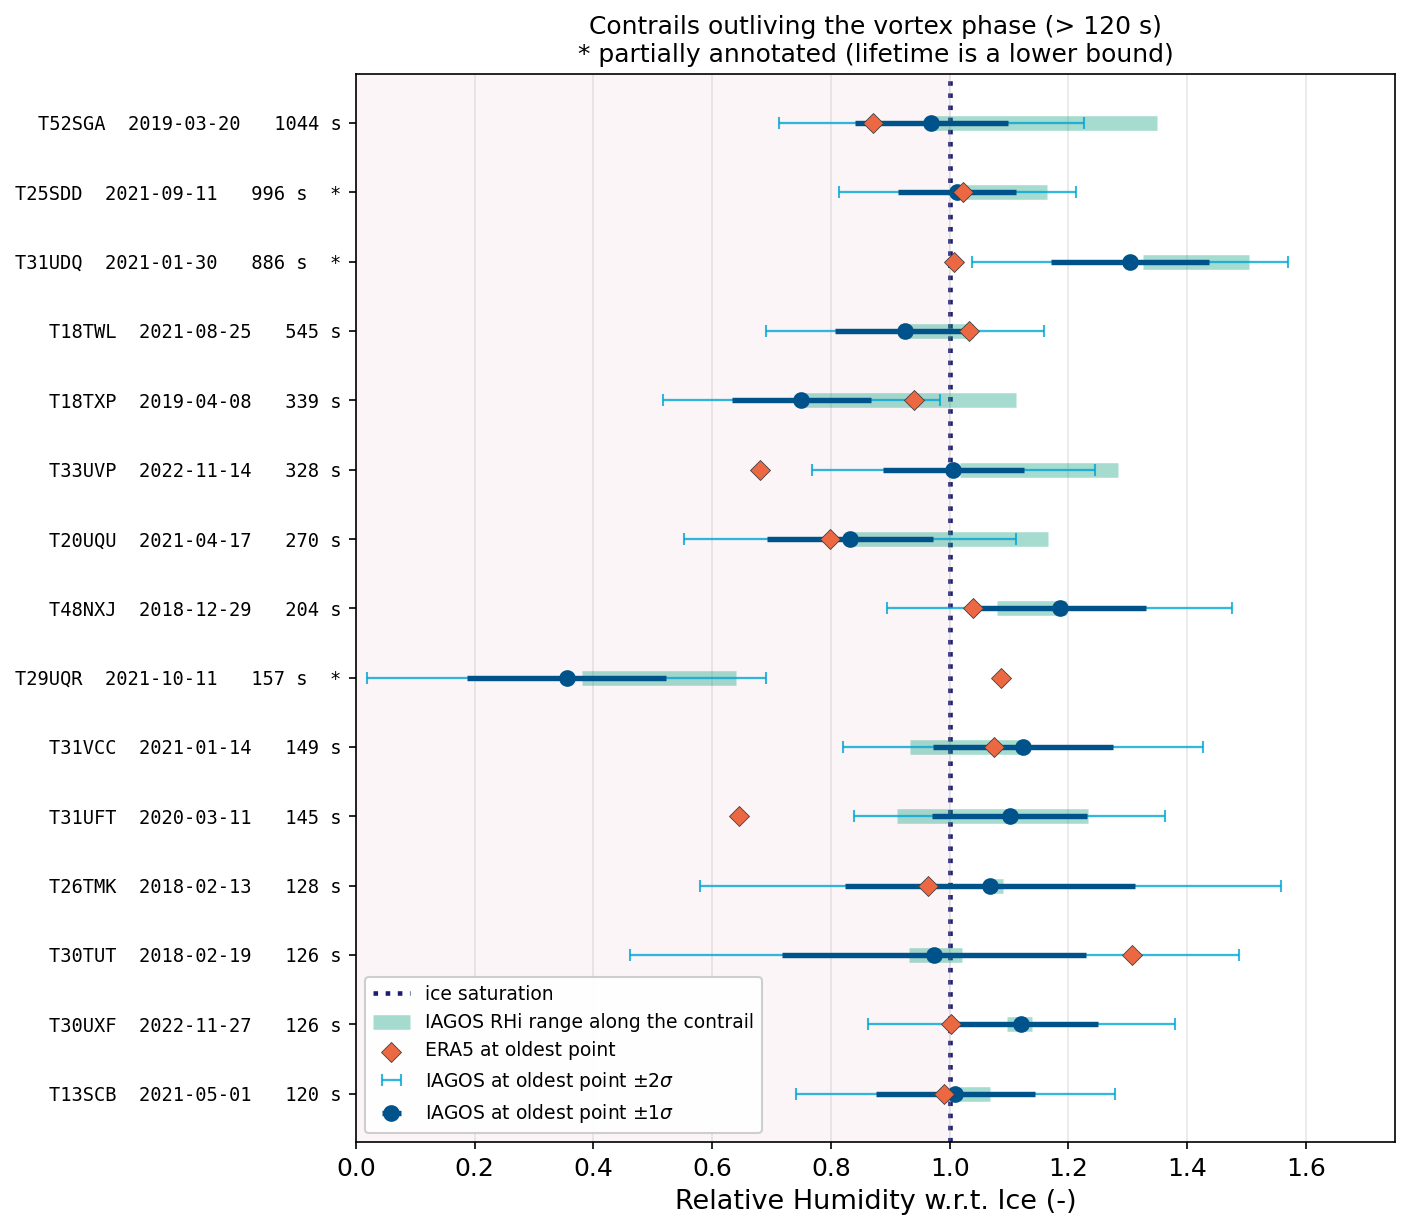

In [30]:
def short_id(scene_id):
    parts = scene_id.split("_")
    return f"{parts[1]}  {parts[3][:4]}-{parts[3][4:6]}-{parts[3][6:8]}"


p = persistent.sort_values("lifetime")
y = np.arange(len(p))

fig, ax = plt.subplots(figsize=(9.5, 0.42 * len(p) + 2.0), dpi=150)

ax.axvline(1.0, color="#1c1c73", lw=2.2, ls=":", zorder=1, label="ice saturation")
ax.axvspan(0, 1.0, color="#a50034", alpha=0.04, zorder=0)

# range measured by IAGOS along the whole contrail
ax.hlines(y, p["rhi_iagos_segment_min"], p["rhi_iagos_segment_max"],
          color="#009b77", lw=7, alpha=0.35, zorder=2,
          label="IAGOS RHi range along the contrail")

# IAGOS at the oldest point, with 1 and 2 sigma
ax.errorbar(p["rhi_iagos_oldest"], y, xerr=2 * p["rhi_sigma"], fmt="none",
            ecolor="#00a6d6", elinewidth=1.1, capsize=3, alpha=0.8, zorder=3,
            label=r"IAGOS at oldest point $\pm 2\sigma$")
ax.errorbar(p["rhi_iagos_oldest"], y, xerr=p["rhi_sigma"], fmt="o", ms=7,
            color="#00538a", ecolor="#00538a", elinewidth=2.6, capsize=0, zorder=4,
            label=r"IAGOS at oldest point $\pm 1\sigma$")

# ERA5 at the same point
ax.scatter(p["rhi_era5_oldest"], y, marker="D", s=46, color="#ec6842",
           edgecolor="0.25", linewidth=0.4, zorder=5, label="ERA5 at oldest point")

labels = [f"{short_id(s)}   {t:.0f} s{'  *' if o == 1 else ''}"
          for s, t, o in zip(p["scene_id"], p["lifetime"], p["out_of_frame"].astype(float))]
ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=9, fontfamily="monospace")
ax.set_ylim(-0.7, len(p) - 0.3)
ax.set_xlim(0, 1.75)
ax.set_xlabel("Relative Humidity w.r.t. Ice (-)")
ax.set_title(f"Contrails outliving the vortex phase (> {PERSISTENT_S:.0f} s)\n"
             "* partially annotated (lifetime is a lower bound)", fontsize=12)
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="lower left", fontsize=9, framealpha=0.95)

fig.tight_layout()
plt.savefig("../figures/fig07_persistent_subsaturated.png", dpi=300,
            bbox_inches="tight", pad_inches=0.1)
plt.show()

In [31]:
def reconcile(frame, label, show_unexplained=True):
    """How many apparently sub-saturated survivors can be explained, and by what."""
    sub = frame[frame["rhi_iagos_oldest"] < 1.0]
    if sub.empty:
        print(f"{label}: no sub-saturated cases")
        return

    within1 = sub["rhi_iagos_oldest"] + sub["rhi_sigma"] >= 1.0
    within2 = sub["rhi_iagos_oldest"] + 2 * sub["rhi_sigma"] >= 1.0
    seg = sub["rhi_iagos_segment_max"] >= 1.0
    era5 = sub["rhi_era5_oldest"] >= 1.0
    any_of = within2 | seg | era5

    print(f"{label}: {len(frame)} cases, {len(sub)} with RHi < 1 at the oldest point")
    print(f"   reached by IAGOS +1 sigma                    : {int(within1.sum()):3d}")
    print(f"   reached by IAGOS +2 sigma                    : {int(within2.sum()):3d}")
    print(f"   IAGOS measures RHi >= 1 somewhere along it   : {int(seg.sum()):3d}")
    print(f"   ERA5 says RHi >= 1 at the same point         : {int(era5.sum()):3d}")
    print(f"   explained by at least one of the three       : {int(any_of.sum()):3d} "
          f"({100 * any_of.mean():.0f}%)")
    print(f"   left unexplained                             : {int((~any_of).sum()):3d}")
    if show_unexplained and (~any_of).any():
        cols = ["lifetime", "temp_iagos_oldest", "rhi_iagos_oldest", "rhi_sigma",
                "rhi_iagos_segment_max", "rhi_era5_oldest", "out_of_frame"]
        print("\n   unexplained cases:")
        print(sub.loc[~any_of, cols].round(3).to_string())
    print()


reconcile(persistent, f"Persistent (> {PERSISTENT_S:.0f} s)")

# A contrail of 10-120 s is still dissipating through the vortex phase and does NOT need
# supersaturation to exist, so an unexplained sub-saturated case here is expected physics,
# not a data problem. Reported only for contrast with the persistent set above.
reconcile(beyond_jet, f"Beyond the jet phase (> {JET_S:.0f} s), still dissipating",
          show_unexplained=False)

cold = res["temp_iagos_oldest"] < res["temp_iagos_oldest"].median()
dry_survivor = (res["lifetime"] >= JET_S) & (res["rhi_iagos_oldest"] < 1.0)
print("Are the sub-saturated survivors the cold ones?")
print(f"   median T, survivors with RHi < 1 : "
      f"{res.loc[dry_survivor, 'temp_iagos_oldest'].median():.1f} K")
print(f"   median T, survivors with RHi >= 1: "
      f"{res.loc[(res['lifetime'] >= JET_S) & (res['rhi_iagos_oldest'] >= 1), 'temp_iagos_oldest'].median():.1f} K")
print(f"   median sigma(RHi) in the coldest half of the dataset: "
      f"{res.loc[cold, 'rhi_sigma'].median():.3f}")
print(f"   median sigma(RHi) in the warmest half              : "
      f"{res.loc[~cold, 'rhi_sigma'].median():.3f}")

Persistent (> 120 s): 15 cases, 6 with RHi < 1 at the oldest point
   reached by IAGOS +1 sigma                    :   3
   reached by IAGOS +2 sigma                    :   4
   IAGOS measures RHi >= 1 somewhere along it   :   5
   ERA5 says RHi >= 1 at the same point         :   3
   explained by at least one of the three       :   6 (100%)
   left unexplained                             :   0

Beyond the jet phase (> 10 s), still dissipating: 96 cases, 66 with RHi < 1 at the oldest point
   reached by IAGOS +1 sigma                    :  22
   reached by IAGOS +2 sigma                    :  31
   IAGOS measures RHi >= 1 somewhere along it   :   7
   ERA5 says RHi >= 1 at the same point         :  10
   explained by at least one of the three       :  34 (52%)
   left unexplained                             :  32

Are the sub-saturated survivors the cold ones?
   median T, survivors with RHi < 1 : 214.0 K
   median T, survivors with RHi >= 1: 217.7 K
   median sigma(RHi) in the coldest

### What this adds

* **The IAGOS humidity uncertainty is not a detail at these temperatures.** The median
  1$\sigma$ on RHi at the oldest point is ~0.12, and it rises from ~0.10 above 226 K to ~0.17
  below 210 K (Spearman $-0.55$ against temperature). Two mechanisms compound: the RHL
  uncertainty itself has a floor that grows in the cold, and converting RHL to RHi multiplies
  it by $e_{\mathrm{sat,liq}}/e_{\mathrm{sat,ice}}$, which also grows as $T$ falls. An RHi of
  0.85 at 208 K and an RHi of 1.0 are not distinguishable measurements.
* **The sub-saturated survivors are the cold ones**, as expected if the sensor is the problem:
  survivors past the jet phase with RHi < 1 sit ~4 K colder in the median than survivors with
  RHi $\geq$ 1.
* **All of them reconcile.** Six contrails outlive the vortex phase with RHi < 1 at the oldest
  point. Five are covered by IAGOS alone — either within 2$\sigma$ or because IAGOS measures
  RHi $\geq 1$ somewhere along the contrail-forming segment. The sixth is the coldest case in
  the whole set (209 K, $\sigma_{\mathrm{RHi}} = 0.17$, RHi = 0.36), is only partially
  annotated, and is the one where ERA5 disagrees with IAGOS most emphatically, reporting
  RHi = 1.09. It is the single case where the in-situ humidity cannot be reconciled with the
  observed contrail on its own terms.
* **The contrast with the shorter-lived contrails is the control.** Below 120 s a contrail is
  still dissipating through the vortex phase and needs no supersaturation to exist, and indeed
  those points sit 4-9 standard deviations below saturation — far outside anything the sensor
  uncertainty could produce. The sub-saturated *survivors* cluster within 2$\sigma$ of
  saturation; the sub-saturated *short-lived* ones do not. That separation is what says the
  uncertainty explanation is doing real work rather than absorbing everything.
* **A single-point humidity is the wrong summary statistic for a 200 km contrail.** The RHi
  range that IAGOS measures along the contrail-forming segment routinely spans 0.2-0.4 for the
  long-lived cases. `rhi_iagos_segment_min/mean/max` are exported so the choice can be made
  explicitly rather than by default.

A caveat the archived uncertainties do **not** cover: the response time of a capacitive
humidity sensor lengthens sharply in the cold, so on entering a moist layer the instrument
reads low for some time afterwards. That is a systematic, one-signed bias on top of the random
$\sigma$ plotted here, and it pushes in exactly the direction needed to explain the remaining
outlier. Quantifying it would need the sensor time constant, which is not in the archive.

## Export

The dry-advection lifetimes and the met state at the oldest point are merged onto the original
collocations CSV, exactly as `figure_7.ipynb` does, and written to
`landsat_sentinel_collocations_20260216_lifetimes_dry_advection.csv`. Columns are populated
only for the annotated Sentinel-2 cases.

In [32]:
EXPORT_COLUMNS = [
    "scene_id",
    # lifetimes
    "lifetime", "lifetime_ground_speed", "lifetime_frozen", "lifetime_air_speed",
    "length", "length_euclidean", "oldest_time",
    "longitude_oldest", "latitude_oldest",
    # IAGOS at the oldest point
    "temp_iagos_oldest", "rhl_iagos_oldest", "rhi_iagos_oldest",
    "air_pressure_iagos_oldest", "efficiency_PS_oldest", "dtlc_iagos_oldest",
    "temp_iagos_oldest_error", "rhl_iagos_oldest_error", "rhi_iagos_oldest_error",
    "rhi_iagos_segment_min", "rhi_iagos_segment_mean", "rhi_iagos_segment_max",
    "temp_iagos_segment_min", "temp_iagos_segment_mean", "n_iagos_segment",
    # ERA5 at the oldest point
    "temp_era5_oldest", "rhl_era5_oldest", "rhi_era5_oldest", "dtlc_era5_oldest",
    "rhi_era5_traj_mean", "rhi_era5_traj_min", "wind_speed_era5_oldest",
    # quality
    "iagos_dt_s", "iagos_in_range", "iagos_validity_temp", "iagos_validity_rhl",
    "iagos_oldest_valid", "era5_level_extrapolated", "era5_time_extrapolated",
    "mismatch_median_m", "mismatch_p90_m", "matched_fraction",
    "advection_displacement_m", "window_saturated", "track_end_reached",
]

lifetimes_df = results[EXPORT_COLUMNS].reset_index(drop=True)

df_full = pd.read_csv(INPUT_CSV, comment="#")
df_out = df_full.merge(lifetimes_df, on="scene_id", how="left")

with open(INPUT_CSV) as f:
    header_lines = [line for line in f if line.startswith("#")]

added_cols_doc = (
    "# Added columns (annotated Sentinel-2 cases only), from notebooks/figure_7_dry_advection.ipynb: "
    "contrail age from a pycontrails DryAdvection run of the IAGOS trajectory, stopped at the "
    "satellite sensing time and matched to the oldest point of the annotation. "
    "lifetime [s], lifetime_ground_speed [s] (geometric estimate of figure_7.ipynb), "
    "lifetime_frozen [s] (no-wind control), lifetime_air_speed [s], "
    "length [m] (along the advected plume), length_euclidean [m], oldest_time [UTC], "
    "longitude_oldest/latitude_oldest [deg]; IAGOS at the oldest point: temp_iagos_oldest [K], "
    "rhl_iagos_oldest [-], rhi_iagos_oldest [-], air_pressure_iagos_oldest [Pa], "
    "efficiency_PS_oldest [-], dtlc_iagos_oldest [K], temp_iagos_oldest_error [K], "
    "rhl_iagos_oldest_error [-], rhi_iagos_oldest_error [-] (IAGOS 1-sigma), "
    "rhi_iagos_segment_min/mean/max [-], temp_iagos_segment_min/mean [K], n_iagos_segment "
    "(IAGOS along the whole contrail-forming segment); ERA5 at the oldest point: "
    "temp_era5_oldest [K], rhl_era5_oldest [-], rhi_era5_oldest [-], dtlc_era5_oldest [K], "
    "rhi_era5_traj_mean/min [-] (along the plume trajectory), wind_speed_era5_oldest [m/s]; "
    "quality: iagos_dt_s [s], iagos_in_range, iagos_validity_temp, iagos_validity_rhl "
    "(IAGOS flags, 0 = good), iagos_oldest_valid, era5_level_extrapolated, "
    "era5_time_extrapolated, mismatch_median_m, mismatch_p90_m, matched_fraction, "
    "advection_displacement_m, window_saturated, track_end_reached.\n"
)

with open(OUTPUT_CSV, "w", newline="") as f:
    f.writelines(header_lines)
    f.write(added_cols_doc)
    df_out.to_csv(f, index=False)

print(f"Wrote {len(df_out)} rows ({lifetimes_df['scene_id'].nunique()} with lifetimes) to {OUTPUT_CSV}")
print(f"Per-case width/age profiles written to {OUTPUT_DIR}")

Wrote 763 rows (195 with lifetimes) to ../data/landsat_sentinel_collocations_20260216_lifetimes_dry_advection.csv
Per-case width/age profiles written to ../data/contrail_evolution/annotations_dry_advection


## What the audit found

With the settings at the top of this notebook, over the 195 annotated Sentinel-2 cases:

**The advection works.** The advected plume traces the annotated contrail to a median residual
of 36 m (p90 165 m, max 1.3 km), against 85 m (p90 1.1 km, max 19 km) for the frozen flight
path. The gap opens up exactly where it should — on the long-lived contrails, whose oldest
plume element has been carried tens of kilometres by the wind (61 km for the longest case).
No case saturates its search window or runs off the end of its advected track.

**The lifetimes move, but the distribution does not.** The median ratio to the geometric
estimate is 0.97, yet individual cases move by a factor 0.5 to 2.1 and by up to 201 s in
absolute terms. Aggregate statistics therefore barely change (96 vs 94 cases above 10 s,
15 vs 17 above 120 s) while per-case values change materially.

**The ground speed was the wrong speed.** Under a spatially uniform wind the plume moves with
the air, so the aircraft separates from its own contrail at the *true air speed*. Replacing
$V_{\mathrm{gs}}$ by $V_{\mathrm{TAS}}$ in the geometric formula already brings the median
ratio to 1.00; what the Lagrangian calculation adds on top is wind shear and curvature along
the plume. If a cheap estimate is ever needed, use the air speed.

**The ERA5 humidity was being read at the wrong place**, and the fix matters where the contrail
is long: $|\Delta \mathrm{RHi}|$ is 0.002 in the median but reaches 0.20, and four cases move
across ice saturation. The IAGOS retrieval was already reading the right *kind* of quantity —
the in-situ state at the emission point — and in this dataset no case trips the tolerance,
range or validity-flag guards; those guards turn an assumption into a checked fact rather than
changing any number. Re-evaluating the Poll-Schumann efficiency at the oldest point instead of
at the intersection changes $\eta$ by up to 12 % and $T_{\mathrm{amb}}-T_{\mathrm{LC}}$ by up
to 2.5 K.

**The apparently impossible points in figure 7 are a humidity-uncertainty problem, not an
advection problem.** All six contrails that outlive the vortex phase at RHi < 1 reconcile with
ice saturation once the IAGOS 1$\sigma$ (median 0.12, rising to 0.17 below 210 K) and the RHi
range along the contrail-forming segment are taken into account; the short-lived sub-saturated
contrails, which need no supersaturation, sit 4-9$\sigma$ below saturation and do not. See
*Temperature, the IAGOS humidity uncertainty, and the persistent sub-saturated contrails*
above.

**Sampling ERA5 along the plume trajectory is not worth it.** It was the most promising of the
"new methods", but ERA5 at 0.25° and 1 h is too smooth for it to matter: the mean and the
minimum RHi along the trajectory differ from the emission-point value by at most 0.038 across
the whole dataset, and no case dips below ice saturation along its path while being
supersaturated at emission. The columns are exported anyway, since they cost nothing and would
become informative with a higher-resolution wind/humidity product.

### Limitations

* **No vertical advection.** The archived ERA5 has no $\omega$, so the plume is advected
  horizontally. At these ages the vertical displacement is $\mathcal{O}(200\,\mathrm{m})$, far
  below what would change the sampled horizontal wind.
* **Level and time padding.** 74 cases contain waypoints outside the two archived pressure
  levels (step climbs, or a top of climb inside the window) and 8 need the ERA5 time axis
  extended backwards by an hour; both are linear extrapolations and both are flagged per case
  (`era5_level_extrapolated`, `era5_time_extrapolated`, `src_level_outside_era5`).
* **The parallax anchor is a rigid translation.** The viewing-geometry displacement varies
  slowly across a scene, so for the 250 km contrails the anchor is only first-order correct.
  The residual statistics above are the evidence that this is adequate.
* **Partially annotated contrails still give lower bounds.** `out_of_frame` cases are clipped
  by the image edge, so their lifetime is a lower bound regardless of how the age is computed.